In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, t

In [3]:
riskforecasting = pd.read_csv('~data/pollution_risk_forecasting.csv')
riskforecasting

,site,time,riskLevelLabel
0,ukc1101-06000,2020-05-14,0.0
1,ukc1101-06000,2020-05-15,0.0
2,ukc1101-06000,2020-05-16,0.0
3,ukc1101-06000,2020-05-17,0.0
4,ukc1101-06000,2020-05-18,0.0
...,...,...,...
187110,ukk4307-33900,2022-09-26,0.0
187111,ukk4307-33900,2022-09-27,0.0
187112,ukk4307-33900,2022-09-28,0.0
187113,ukk4307-33900,2022-09-29,0.0


In [4]:
feature_na = pd.read_csv('~data/feature_extraction_15x15.csv')
feature_na

,time,site,BBP_1x1_median,CDM_1x1_median,SPM_1x1_median,KD490_1x1_median,ZSD_1x1_median,CHL_1x1_median,BBP_1x1_mean,CDM_1x1_mean,...,SPM_15x15_q1,KD490_15x15_q1,ZSD_15x15_q1,CHL_15x15_q1,BBP_15x15_q3,CDM_15x15_q3,SPM_15x15_q3,KD490_15x15_q3,ZSD_15x15_q3,CHL_15x15_q3
0,2020-01-01,ukc1101-06000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2020-01-01,ukc1101-06100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2020-01-01,ukc1101-06200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2020-01-01,ukc1202-06300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.218511,0.155469,4.414686,2.392838,NaN,NaN,2.355747,0.164187,4.705874,2.620098
4,2020-01-01,ukc1202-06400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.088109,0.147391,4.552876,2.188390,NaN,NaN,2.351558,0.159994,5.009740,2.510444
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
471275,2022-12-31,ukk4306-22800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
471276,2022-12-31,ukk4306-22900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
471277,2022-12-31,ukk4306-23000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
471278,2022-12-31,ukk4307-33800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
feature_neg = pd.read_csv('~data/feature_extraction_15x15_neg10.csv')
feature_neg

,time,site,BBP_1x1_median,CDM_1x1_median,SPM_1x1_median,KD490_1x1_median,ZSD_1x1_median,CHL_1x1_median,BBP_1x1_mean,CDM_1x1_mean,...,SPM_15x15_q1,KD490_15x15_q1,ZSD_15x15_q1,CHL_15x15_q1,BBP_15x15_q3,CDM_15x15_q3,SPM_15x15_q3,KD490_15x15_q3,ZSD_15x15_q3,CHL_15x15_q3
0,2020-01-01,ukc1101-06000,-10.0,-10.0,-10.000000,-10.000000,-10.000000,-10.000000,-10.0,-10.0,...,-10.000000,-10.000000,-10.000000,-10.000000,-10.0,-10.0,-10.000000,-10.000000,-10.000000,-10.000000
1,2020-01-01,ukc1101-06100,-10.0,-10.0,-10.000000,-10.000000,-10.000000,-10.000000,-10.0,-10.0,...,-10.000000,-10.000000,-10.000000,-10.000000,-10.0,-10.0,-10.000000,-10.000000,-10.000000,-10.000000
2,2020-01-01,ukc1101-06200,-10.0,-10.0,-10.000000,-10.000000,-10.000000,-10.000000,-10.0,-10.0,...,-10.000000,-10.000000,-10.000000,-10.000000,-10.0,-10.0,-10.000000,-10.000000,-10.000000,-10.000000
3,2020-01-01,ukc1202-06300,-10.0,-10.0,2.275929,0.160749,4.534724,2.531511,-10.0,-10.0,...,2.275929,0.160749,4.534724,2.531511,-10.0,-10.0,2.275929,0.160749,4.534724,2.531511
4,2020-01-01,ukc1202-06400,-10.0,-10.0,2.215205,0.155033,4.743151,2.385542,-10.0,-10.0,...,2.215205,0.155033,4.743151,2.385542,-10.0,-10.0,2.215205,0.155033,4.743151,2.385542
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
471275,2022-12-31,ukk4306-22800,-10.0,-10.0,-10.000000,-10.000000,-10.000000,-10.000000,-10.0,-10.0,...,-10.000000,-10.000000,-10.000000,-10.000000,-10.0,-10.0,-10.000000,-10.000000,-10.000000,-10.000000
471276,2022-12-31,ukk4306-22900,-10.0,-10.0,-10.000000,-10.000000,-10.000000,-10.000000,-10.0,-10.0,...,-10.000000,-10.000000,-10.000000,-10.000000,-10.0,-10.0,-10.000000,-10.000000,-10.000000,-10.000000
471277,2022-12-31,ukk4306-23000,-10.0,-10.0,-10.000000,-10.000000,-10.000000,-10.000000,-10.0,-10.0,...,-10.000000,-10.000000,-10.000000,-10.000000,-10.0,-10.0,-10.000000,-10.000000,-10.000000,-10.000000
471278,2022-12-31,ukk4307-33800,-10.0,-10.0,-10.000000,-10.000000,-10.000000,-10.000000,-10.0,-10.0,...,-10.000000,-10.000000,-10.000000,-10.000000,-10.0,-10.0,-10.000000,-10.000000,-10.000000,-10.000000


In [8]:
feature_zero = pd.read_csv('~data/feature_extraction_15x15_zero.csv')
feature_zero

,time,site,BBP_1x1_median,CDM_1x1_median,SPM_1x1_median,KD490_1x1_median,ZSD_1x1_median,CHL_1x1_median,BBP_1x1_mean,CDM_1x1_mean,...,SPM_15x15_q1,KD490_15x15_q1,ZSD_15x15_q1,CHL_15x15_q1,BBP_15x15_q3,CDM_15x15_q3,SPM_15x15_q3,KD490_15x15_q3,ZSD_15x15_q3,CHL_15x15_q3
0,2020-01-01,ukc1101-06000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
1,2020-01-01,ukc1101-06100,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
2,2020-01-01,ukc1101-06200,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
3,2020-01-01,ukc1202-06300,0.0,0.0,2.275929,0.160749,4.534724,2.531511,0.0,0.0,...,2.275929,0.160749,4.534724,2.531511,0.0,0.0,2.275929,0.160749,4.534724,2.531511
4,2020-01-01,ukc1202-06400,0.0,0.0,2.215205,0.155033,4.743151,2.385542,0.0,0.0,...,2.215205,0.155033,4.743151,2.385542,0.0,0.0,2.215205,0.155033,4.743151,2.385542
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
471275,2022-12-31,ukk4306-22800,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
471276,2022-12-31,ukk4306-22900,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
471277,2022-12-31,ukk4306-23000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
471278,2022-12-31,ukk4307-33800,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000


# Feature Value Comparison

### Feature Dataset without Filling Missing Value

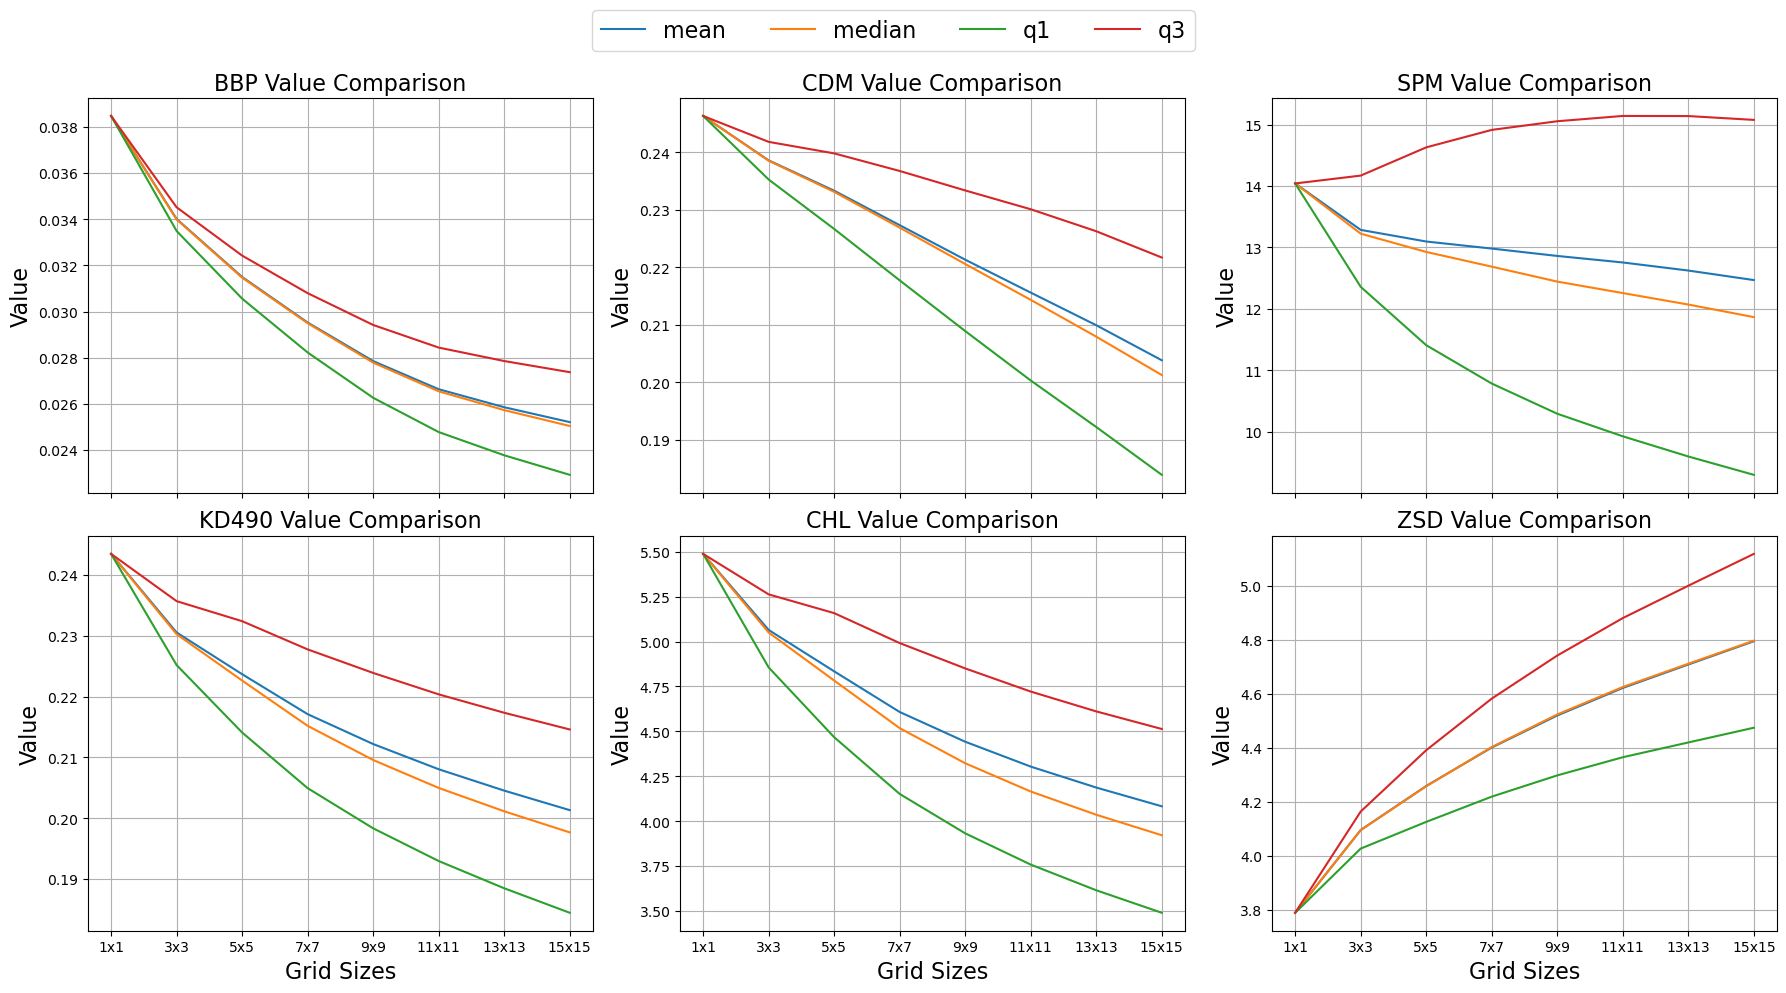

In [35]:
features = ['BBP', 'CDM', 'SPM', 'KD490', 'CHL', 'ZSD']
sizes = ['1x1', '3x3', '5x5', '7x7', '9x9', '11x11', '13x13', '15x15']
statistics = ['mean', 'median', 'q1', 'q3']

fig, axs = plt.subplots(2, 3, figsize=(18, 10), sharex=True)

for ax, feature in zip(axs.ravel(), features):
    
    for statistic in statistics:
        columns = [f'{feature}_{res}_{statistic}' for res in sizes]
        feature_na[columns].mean().plot(ax=ax, label=statistic) 
        
    ax.set_title(f'{feature} Value Comparison', fontsize=16)
    ax.set_xticks(range(len(sizes)))
    ax.set_xticklabels(sizes, rotation=0)
    ax.set_ylabel('Value', fontsize=16)
    ax.set_xlabel('Grid Sizes', fontsize=16)
    ax.grid(True)

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, statistics, ncol=4, loc='upper center', fontsize=16)  

plt.tight_layout()
plt.subplots_adjust(top=0.9)
plt.show()

### Feature Dataset filled with Neg

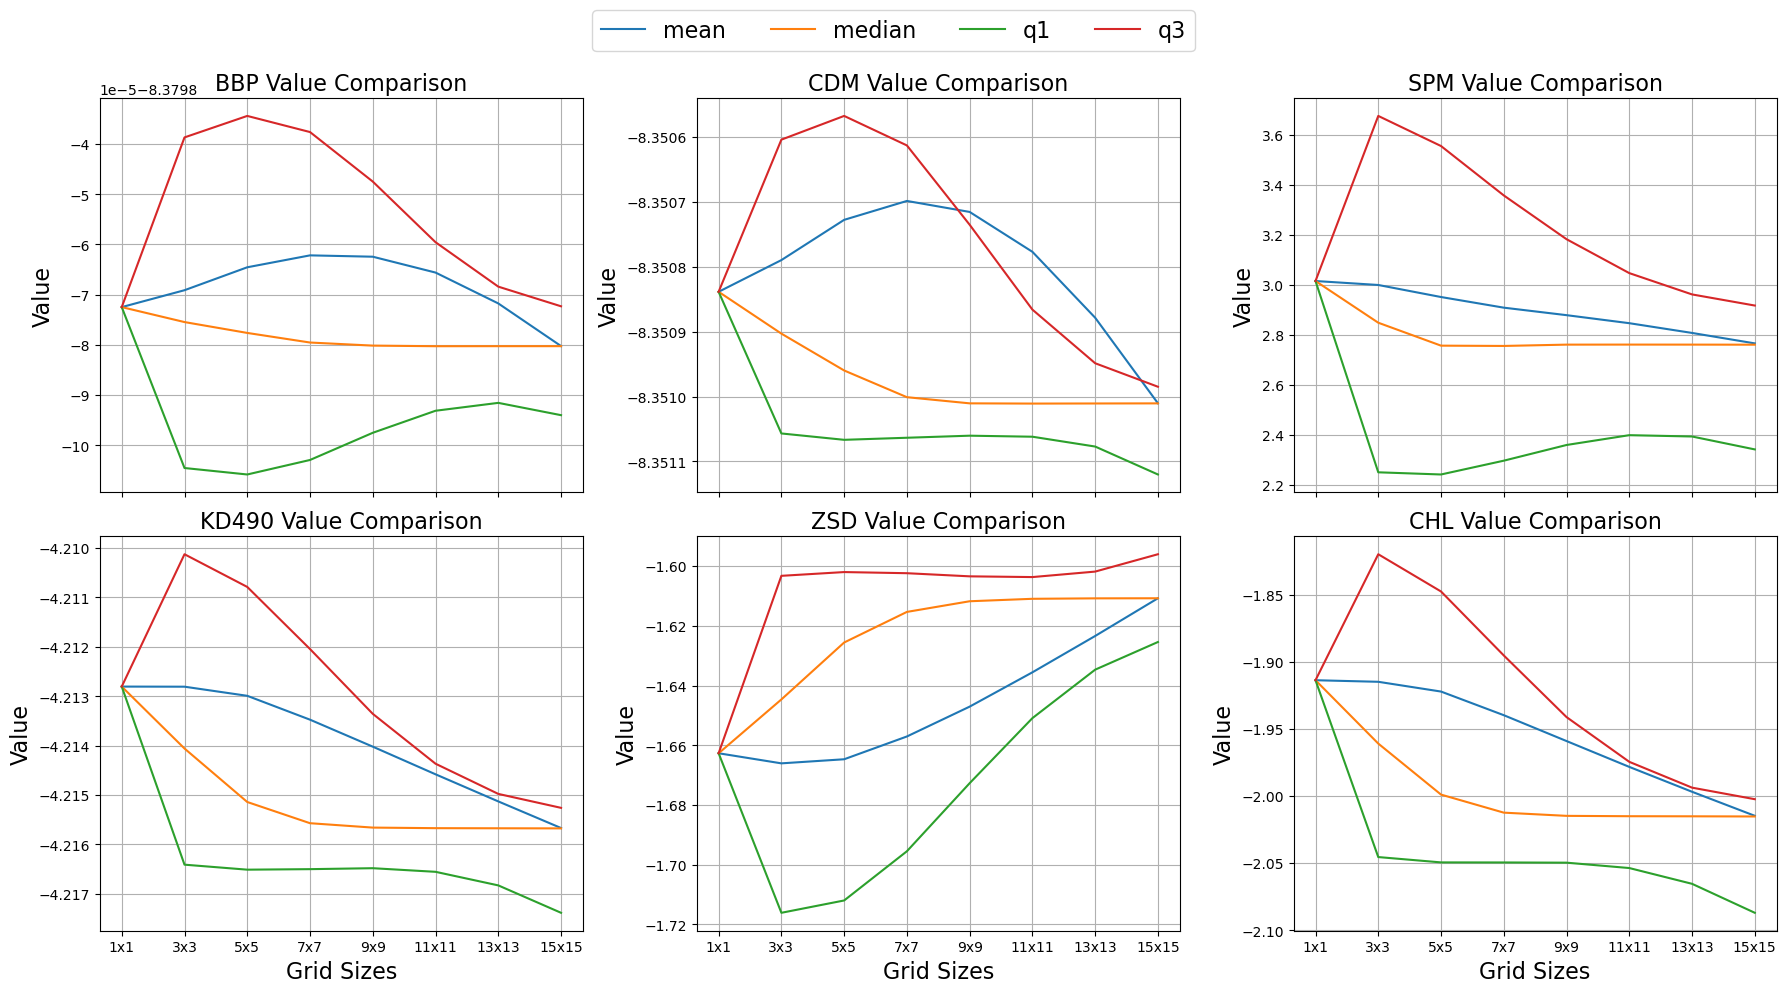

In [27]:
features = ['BBP', 'CDM', 'SPM', 'KD490', 'ZSD', 'CHL']
sizes = ['1x1', '3x3', '5x5', '7x7', '9x9', '11x11', '13x13', '15x15']
statistics = ['mean', 'median', 'q1', 'q3']

fig, axs = plt.subplots(2, 3, figsize=(18, 10), sharex=True)

for ax, feature in zip(axs.ravel(), features):
    
    for statistic in statistics:
        columns = [f'{feature}_{res}_{statistic}' for res in sizes]
        feature_neg[columns].mean().plot(ax=ax, label=statistic) 
        
    ax.set_title(f'{feature} Value Comparison', fontsize=16)
    ax.set_xticks(range(len(sizes)))
    ax.set_xticklabels(sizes, rotation=0)
    ax.set_ylabel('Value', fontsize=16)
    ax.set_xlabel('Grid Sizes', fontsize=16)
    ax.grid(True)

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, statistics, ncol=4, loc='upper center', fontsize=16)  

plt.tight_layout()
plt.subplots_adjust(top=0.9)
plt.show()

In [6]:
data = []

for col in feature_neg.columns:
    if col not in ['time', 'site']:
        feat, size_stat = col.split('_')[0], '_'.join(col.split('_')[1:])
        size, statistic = size_stat.split('_')[0], '_'.join(size_stat.split('_')[1:])
        
        mean_value = feature_neg[col].mean()

        data.append([feat, size, statistic, mean_value])

feature_mean_neg = pd.DataFrame(data, columns=['feature', 'size', 'statistics', 'mean'])
feature_mean_neg

,feature,size,statistics,mean
0,BBP,1x1,median,-8.379872
1,CDM,1x1,median,-8.350839
2,SPM,1x1,median,3.014654
3,KD490,1x1,median,-4.212805
4,ZSD,1x1,median,-1.662674
...,...,...,...,...
187,CDM,15x15,q3,-8.350985
188,SPM,15x15,q3,2.916493
189,KD490,15x15,q3,-4.215261
190,ZSD,15x15,q3,-1.596026


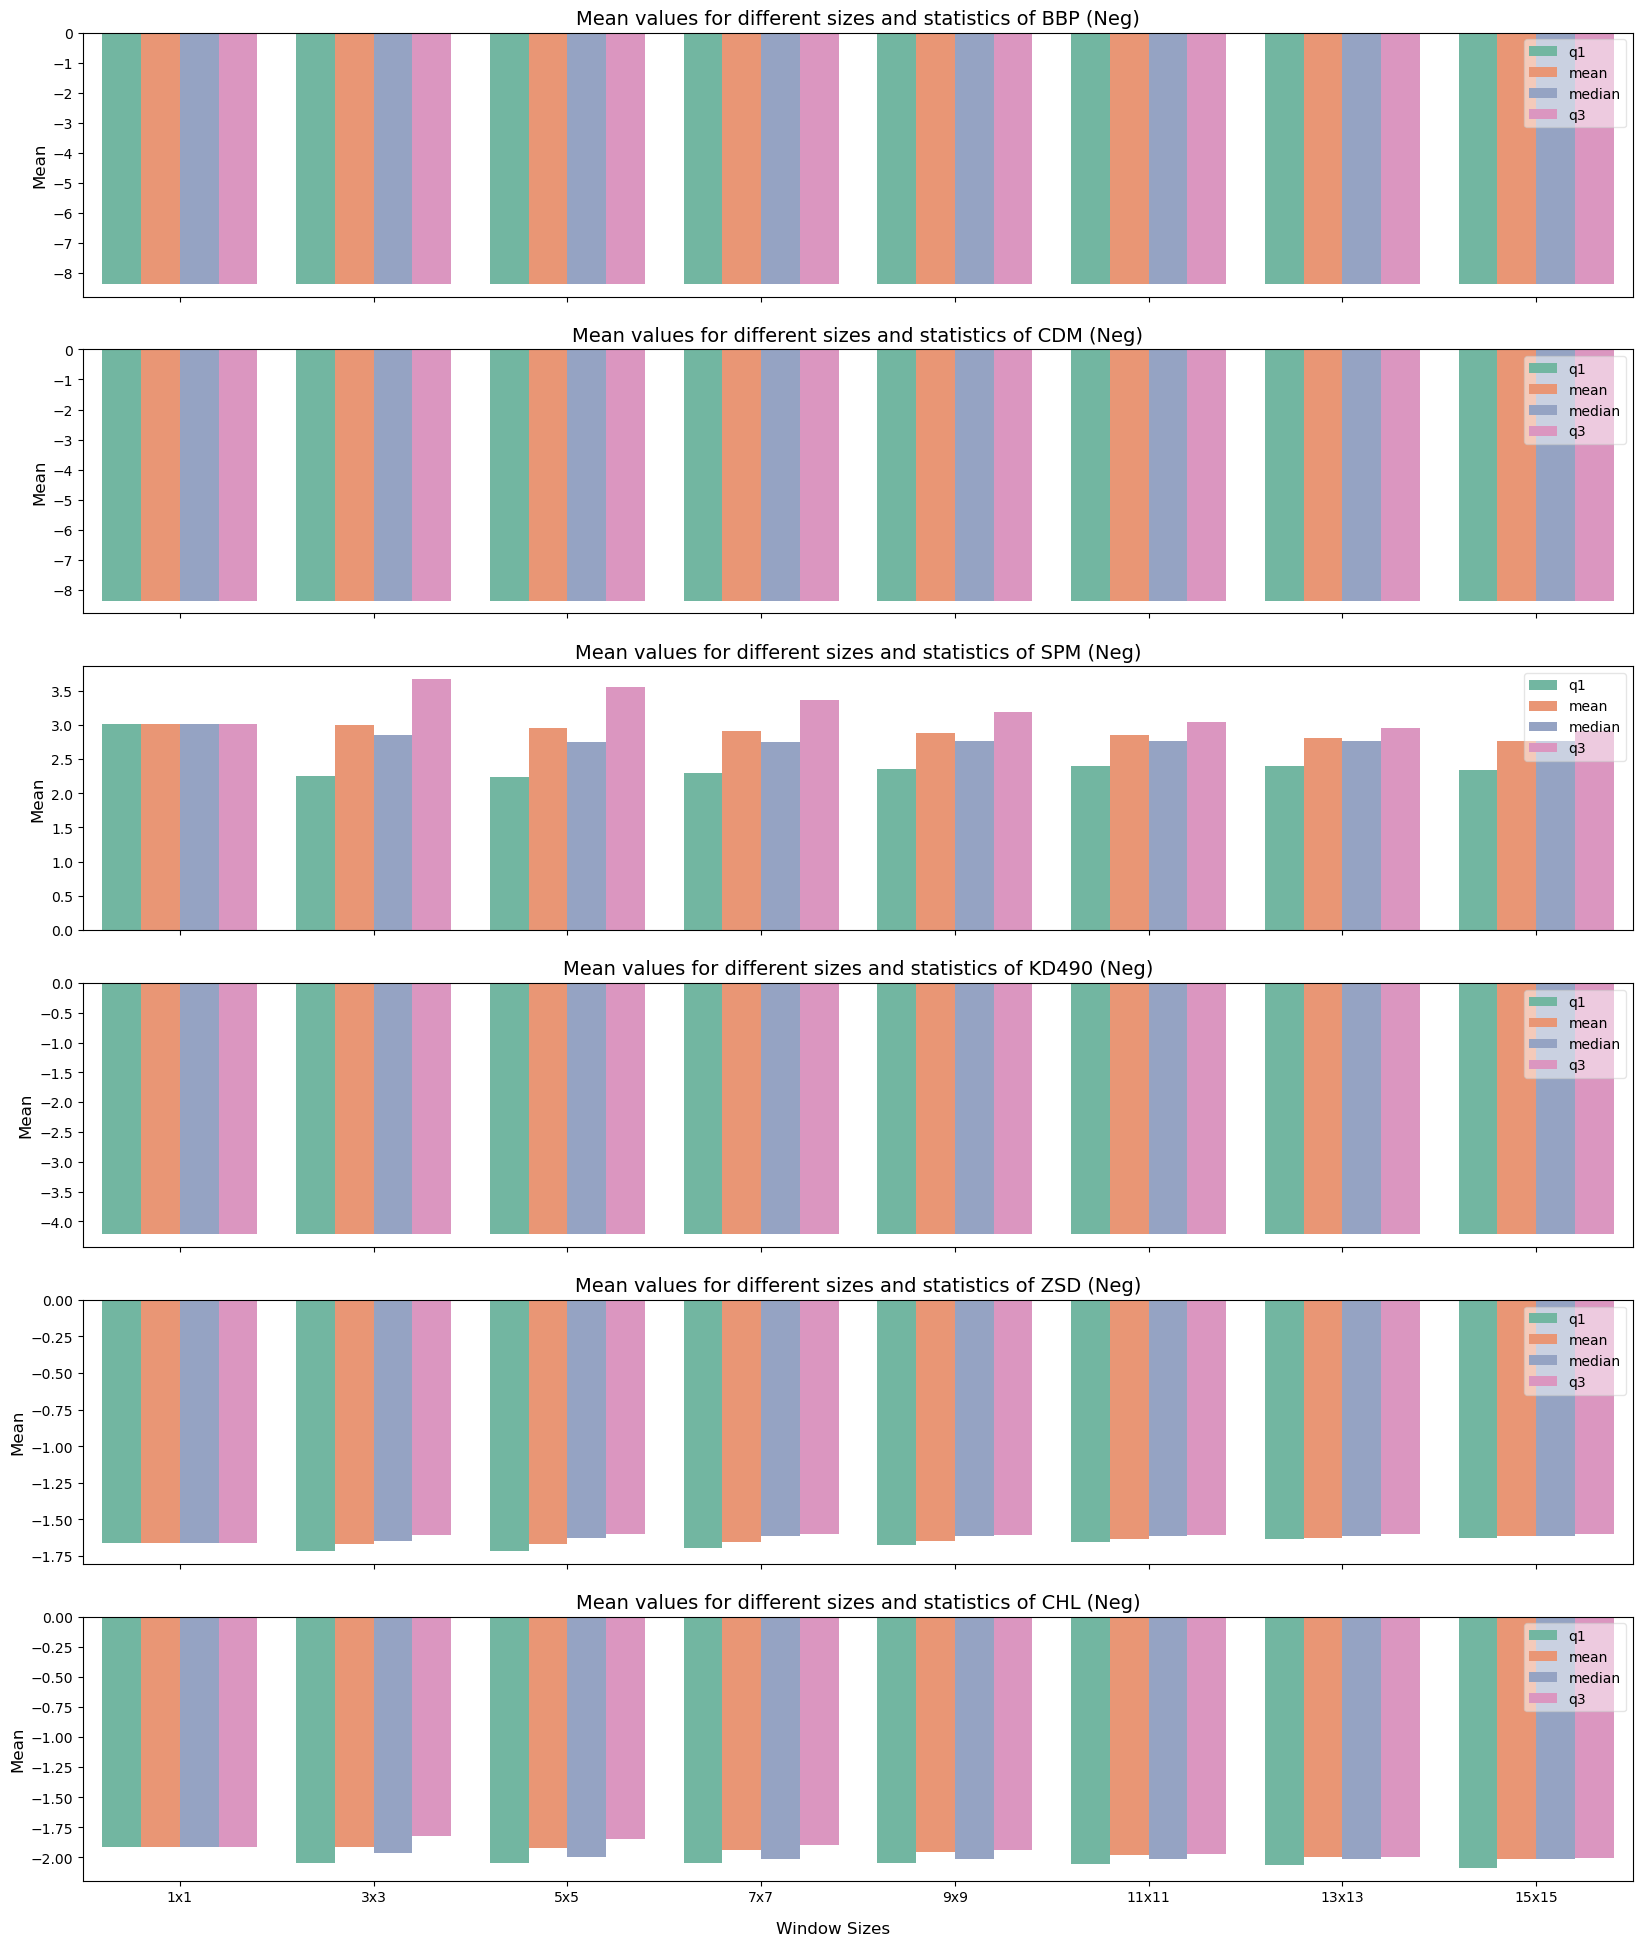

In [7]:
features = feature_mean_neg['feature'].unique()
feature_mean_neg['size_num'] = feature_mean_neg['size'].apply(lambda size_str: int(size_str.split('x')[0]))

sns.set_palette("Set2")

fig, axs = plt.subplots(len(features), 1, figsize=(20, 4 * len(features)), sharex=True)

for idx, feat in enumerate(features):
    feat_data = feature_mean_neg[feature_mean_neg['feature'] == feat].sort_values('size_num')

    sns.barplot(x='size', y='mean', hue='statistics', data=feat_data, ax=axs[idx],
                hue_order=['q1', 'mean', 'median', 'q3'])

    axs[idx].set_title(f'Mean values for different sizes and statistics of {feat} (Neg)', fontsize=14)
    axs[idx].set_xlabel('')
    axs[idx].set_ylabel('Mean', fontsize=12)
    axs[idx].legend(loc='upper right',framealpha=0.5)

fig.text(0.5, 0.09, 'Window Sizes', ha='center', va='center', fontsize=12)

plt.show()

### Feature Dataset filled with Zero

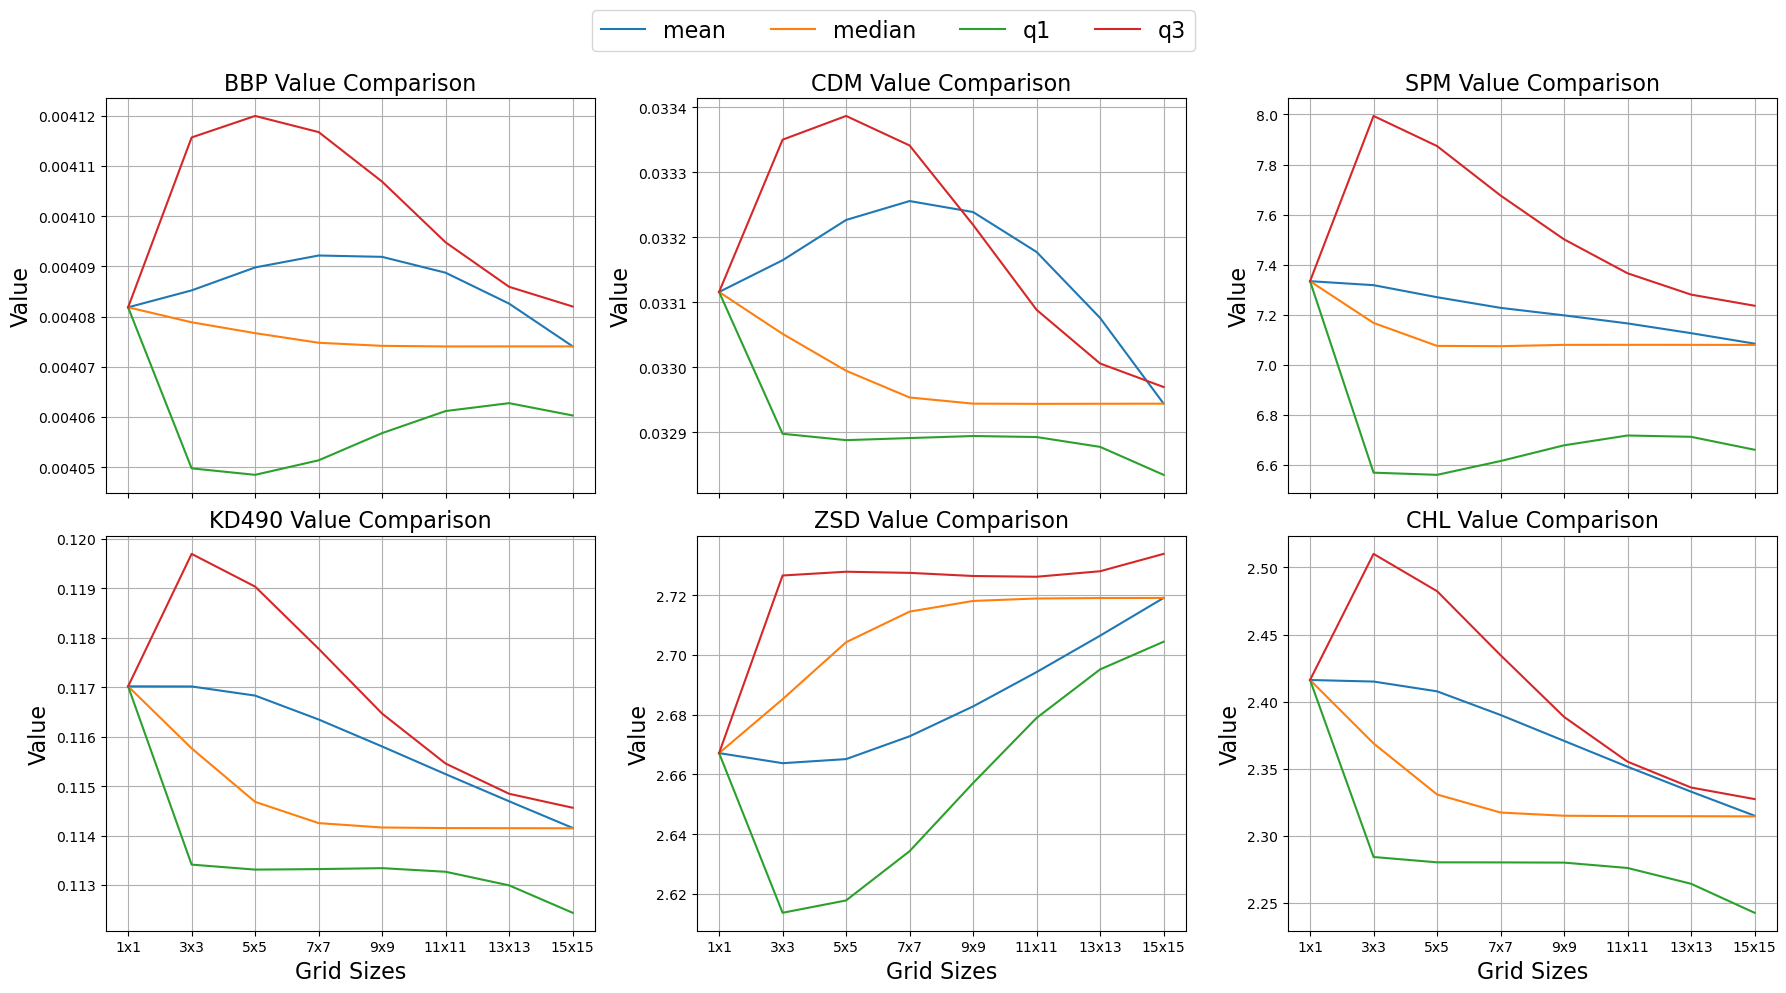

In [28]:
features = ['BBP', 'CDM', 'SPM', 'KD490', 'ZSD', 'CHL']
sizes = ['1x1', '3x3', '5x5', '7x7', '9x9', '11x11', '13x13', '15x15']
statistics = ['mean', 'median', 'q1', 'q3']

fig, axs = plt.subplots(2, 3, figsize=(18, 10), sharex=True)

for ax, feature in zip(axs.ravel(), features):
    
    for statistic in statistics:
        columns = [f'{feature}_{res}_{statistic}' for res in sizes]
        feature_zero[columns].mean().plot(ax=ax, label=statistic) 
        
    ax.set_title(f'{feature} Value Comparison', fontsize=16)
    ax.set_xticks(range(len(sizes)))
    ax.set_xticklabels(sizes, rotation=0)
    ax.set_ylabel('Value', fontsize=16)
    ax.set_xlabel('Grid Sizes', fontsize=16)
    ax.grid(True)

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, statistics, ncol=4, loc='upper center', fontsize=16)  

plt.tight_layout()
plt.subplots_adjust(top=0.9)
plt.show()

In [9]:
data = []

for col in feature_zero.columns:
    if col not in ['time', 'site']:
        feat, size_stat = col.split('_')[0], '_'.join(col.split('_')[1:])
        size, statistic = size_stat.split('_')[0], '_'.join(size_stat.split('_')[1:])
        
        mean_value = feature_zero[col].mean()

        data.append([feat, size, statistic, mean_value])

feature_mean_zero = pd.DataFrame(data, columns=['feature', 'size', 'statistics', 'mean'])
feature_mean_zero

,feature,size,statistics,mean
0,BBP,1x1,median,0.004082
1,CDM,1x1,median,0.033116
2,SPM,1x1,median,7.333551
3,KD490,1x1,median,0.117020
4,ZSD,1x1,median,2.667152
...,...,...,...,...
187,CDM,15x15,q3,0.032970
188,SPM,15x15,q3,7.235390
189,KD490,15x15,q3,0.114564
190,ZSD,15x15,q3,2.733800


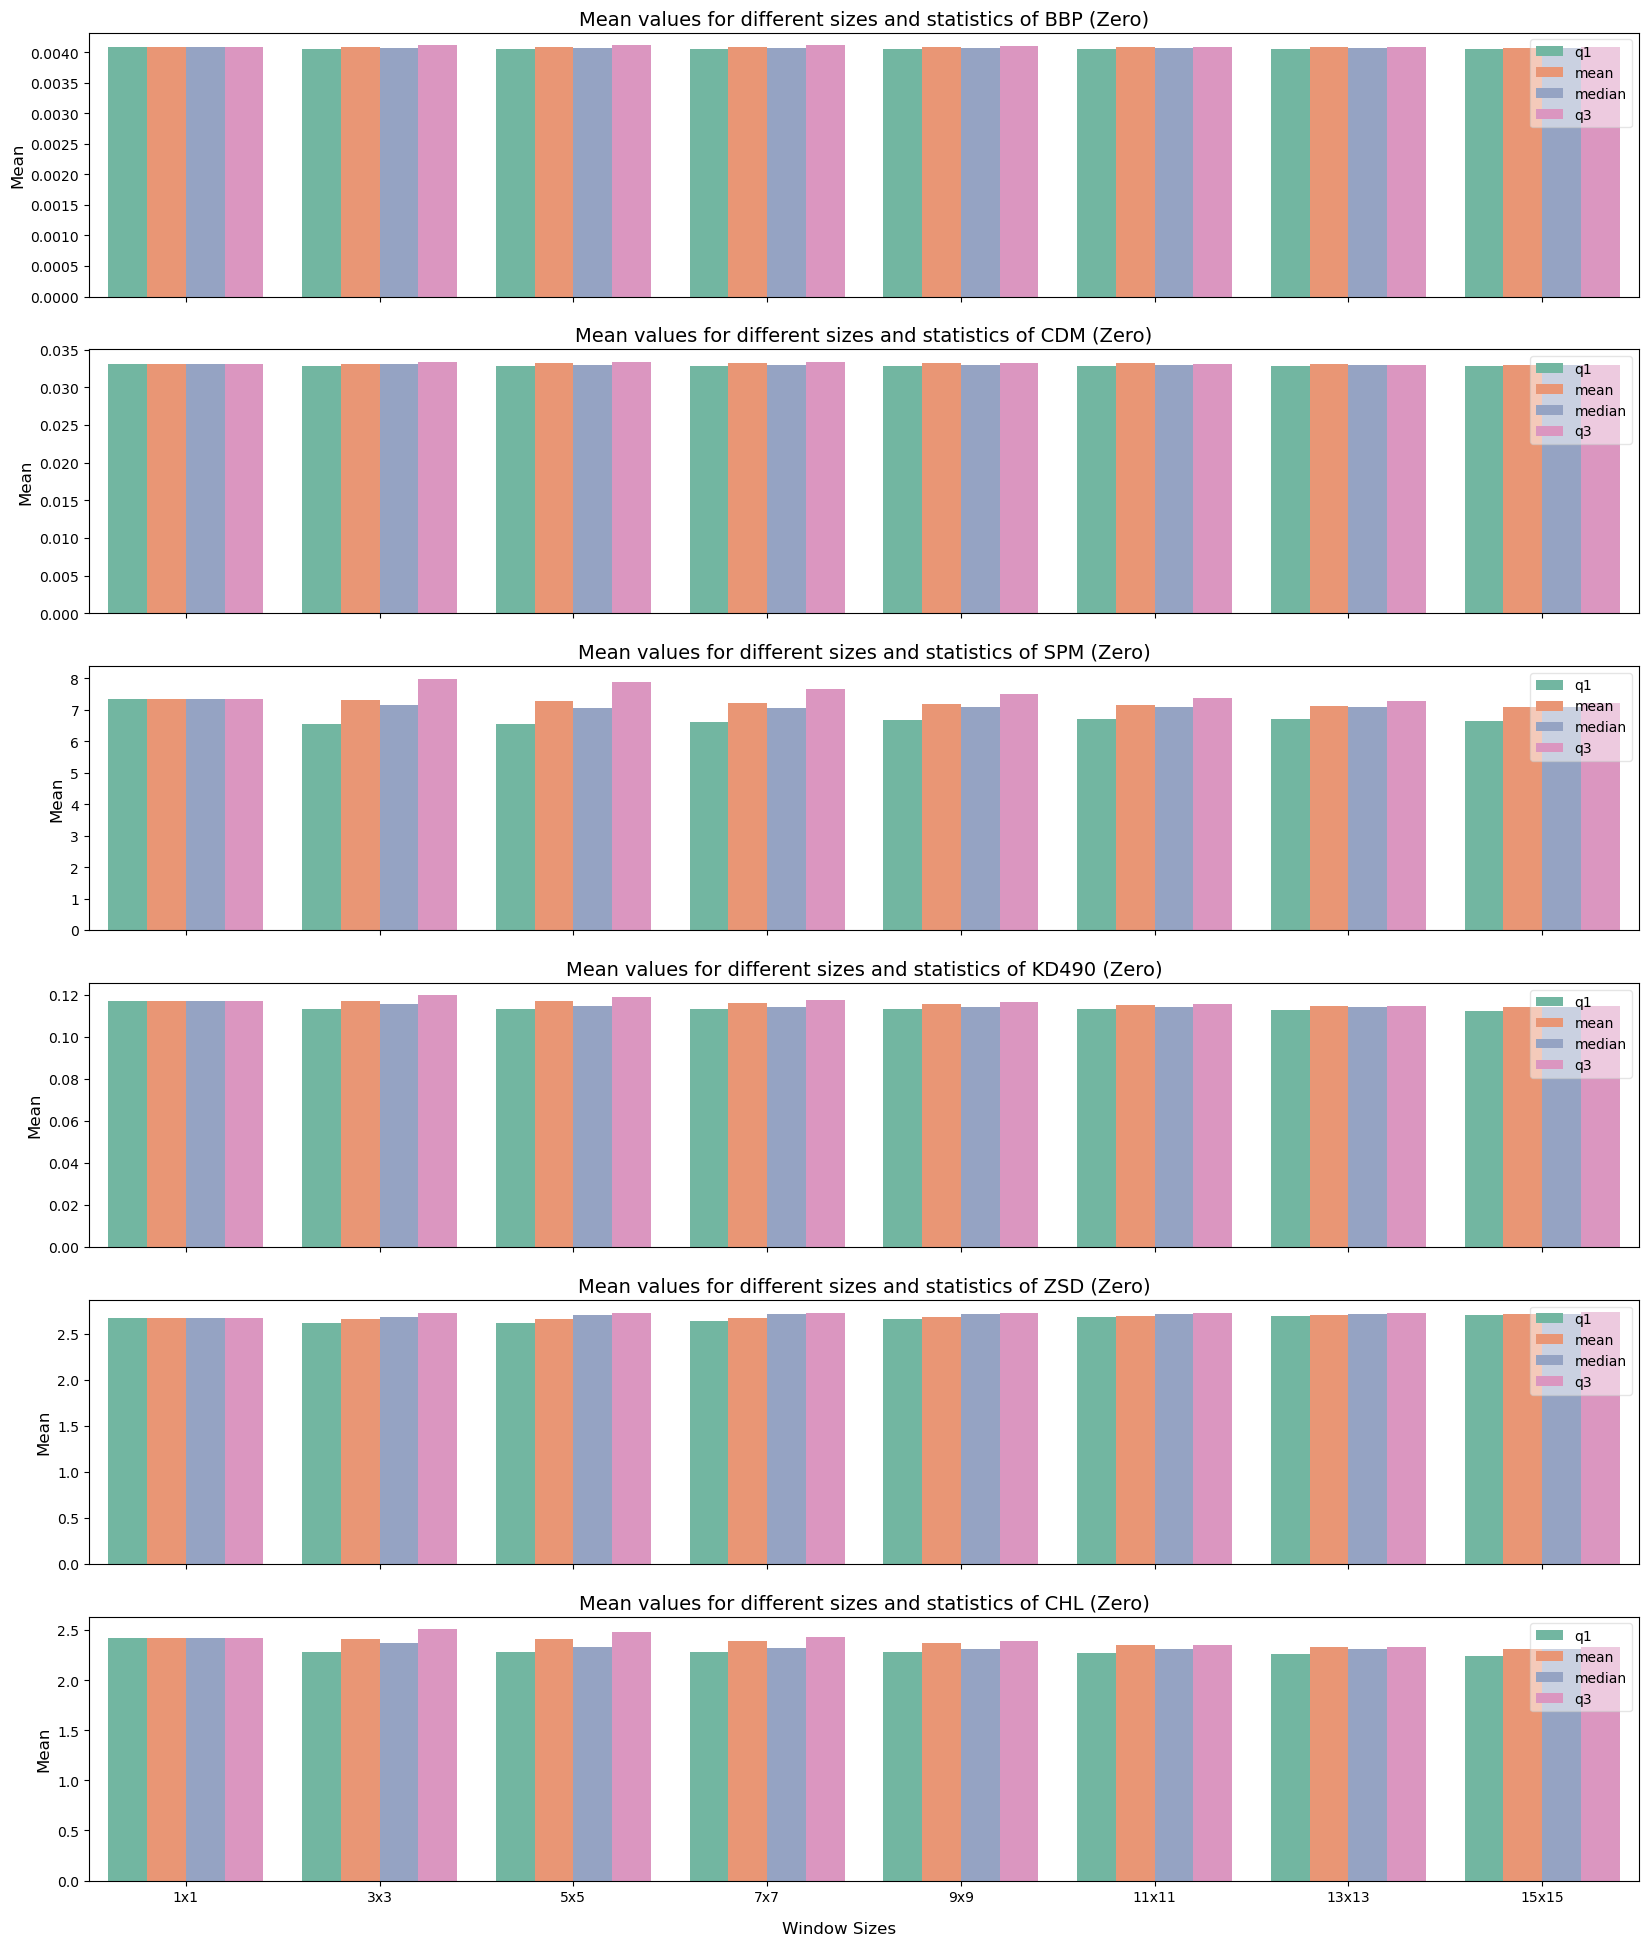

In [10]:
features = feature_mean_zero['feature'].unique()
feature_mean_zero['size_num'] = feature_mean_zero['size'].apply(lambda size_str: int(size_str.split('x')[0]))

sns.set_palette("Set2")

fig, axs = plt.subplots(len(features), 1, figsize=(20, 4 * len(features)), sharex=True)

for idx, feat in enumerate(features):
    feat_data = feature_mean_zero[feature_mean_zero['feature'] == feat].sort_values('size_num')

    sns.barplot(x='size', y='mean', hue='statistics', data=feat_data, ax=axs[idx],
                hue_order=['q1', 'mean', 'median', 'q3'])

    axs[idx].set_title(f'Mean values for different sizes and statistics of {feat} (Zero)', fontsize=14)
    axs[idx].set_xlabel('')
    axs[idx].set_ylabel('Mean', fontsize=12)
    axs[idx].legend(loc='upper right',framealpha=0.5)

fig.text(0.5, 0.09, 'Window Sizes', ha='center', va='center', fontsize=12)

plt.show()

# RiskLevelLabel vs. 6 Features

#### Feature Dataset without filling Missing Value

In [9]:
df = pd.merge(riskforecasting, feature_na, on=['site','time'])
df

,site,time,riskLevelLabel,BBP_1x1_median,CDM_1x1_median,SPM_1x1_median,KD490_1x1_median,ZSD_1x1_median,CHL_1x1_median,BBP_1x1_mean,...,SPM_15x15_q1,KD490_15x15_q1,ZSD_15x15_q1,CHL_15x15_q1,BBP_15x15_q3,CDM_15x15_q3,SPM_15x15_q3,KD490_15x15_q3,ZSD_15x15_q3,CHL_15x15_q3
0,ukc1101-06000,2020-05-14,0.0,NaN,NaN,9.016005,NaN,NaN,NaN,NaN,...,4.633350,0.658758,1.337249,23.402420,0.014399,0.648437,6.829493,0.782075,1.376949,30.399586
1,ukc1101-06000,2020-05-15,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,8.102808,0.389522,1.773775,10.416777,NaN,NaN,8.102808,0.394867,1.792657,10.639543
2,ukc1101-06000,2020-05-16,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.951647,0.255377,2.511375,5.363088,NaN,NaN,1.347192,0.270816,2.670747,5.887294
3,ukc1101-06000,2020-05-17,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ukc1101-06000,2020-05-18,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187107,ukk4307-33900,2022-09-26,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5.116745,0.182074,3.801842,3.106306,NaN,NaN,7.625628,0.186561,3.910818,3.232617
187108,ukk4307-33900,2022-09-27,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
187109,ukk4307-33900,2022-09-28,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.906127,0.142193,5.212851,2.060148,NaN,NaN,4.906127,0.142495,5.225880,2.067529
187110,ukk4307-33900,2022-09-29,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,7.659460,0.148248,4.761873,2.209768,NaN,NaN,11.234165,0.153901,4.975588,2.352627


In [59]:
correlations = df.corr()['riskLevelLabel']

# For features
features = ['BBP', 'CDM', 'SPM', 'KD490', 'ZSD', 'CHL']
highest_feature_correlations = {}

for feature in features:
    feature_correlations = {key: correlations[key] for key in correlations.keys() if feature in key}
    max_correlation_key = max(feature_correlations, key=lambda k: abs(feature_correlations[k]))
    highest_feature_correlations[feature] = (max_correlation_key, feature_correlations[max_correlation_key])


# For grid sizes
grid_sizes = [f"{i}x{i}" for i in range(1, 16, 2)]
highest_grid_correlations = {}

for grid in grid_sizes:
    grid_correlations = {key: correlations[key] for key in correlations.keys() if grid in key}
    max_correlation_key = max(grid_correlations, key=lambda k: abs(grid_correlations[k]))
    highest_grid_correlations[grid] = (max_correlation_key, grid_correlations[max_correlation_key])

/var/folders/r5/x64ktbgx58365__7s6m8nvqh0000gn/T/ipykernel_1313/2261963275.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlations = df.corr()['riskLevelLabel']


In [62]:
highest_feature_correlations

{'BBP': ('BBP_7x7_median', 0.03570957401702285),
 'CDM': ('CDM_1x1_median', -0.028824792376234212),
 'SPM': ('SPM_1x1_median', 0.06684016462875776),
 'KD490': ('KD490_15x15_q1', 0.013537296229456272),
 'ZSD': ('ZSD_15x15_q3', -0.011568341544003132),
 'CHL': ('CHL_5x5_q3', -0.012248916528221356)}

In [63]:
highest_grid_correlations

{'1x1': ('SPM_1x1_median', 0.06684016462875776),
 '3x3': ('SPM_3x3_q3', 0.056730684634054486),
 '5x5': ('SPM_5x5_mean', 0.05826415683282747),
 '7x7': ('SPM_7x7_q3', 0.05872178750712021),
 '9x9': ('SPM_9x9_q3', 0.0571658022684985),
 '11x11': ('SPM_11x11_q3', 0.05534619111923884),
 '13x13': ('SPM_13x13_q3', 0.0530032954662795),
 '15x15': ('SPM_15x15_q3', 0.05224649049670442)}

In [47]:
df_corr_pearson.sort_values('riskLevelLabel',key=abs,ascending=False).head(11)

,riskLevelLabel,BBP_1x1_median,CDM_1x1_median,SPM_1x1_median,KD490_1x1_median,ZSD_1x1_median,CHL_1x1_median,BBP_1x1_mean,CDM_1x1_mean,SPM_1x1_mean,...,SPM_15x15_q1,KD490_15x15_q1,ZSD_15x15_q1,CHL_15x15_q1,BBP_15x15_q3,CDM_15x15_q3,SPM_15x15_q3,KD490_15x15_q3,ZSD_15x15_q3,CHL_15x15_q3
riskLevelLabel,1.000000,0.023234,-0.028825,0.066840,-0.000384,-0.008368,-0.005257,0.023234,-0.028825,0.066840,...,0.044435,0.013537,-0.002382,0.010493,0.030468,-0.005227,0.052246,-0.003199,-0.011568,-0.006270
SPM_1x1_median,0.066840,0.644808,0.251321,1.000000,0.147231,-0.234277,0.097722,0.644808,0.251321,1.000000,...,0.832782,0.316486,-0.259173,0.277542,0.618269,0.215140,0.854747,0.214475,-0.301975,0.168527
SPM_1x1_q1,0.066840,0.644808,0.251321,1.000000,0.147231,-0.234277,0.097722,0.644808,0.251321,1.000000,...,0.832782,0.316486,-0.259173,0.277542,0.618269,0.215140,0.854747,0.214475,-0.301975,0.168527
SPM_1x1_q3,0.066840,0.644808,0.251321,1.000000,0.147231,-0.234277,0.097722,0.644808,0.251321,1.000000,...,0.832782,0.316486,-0.259173,0.277542,0.618269,0.215140,0.854747,0.214475,-0.301975,0.168527
SPM_1x1_mean,0.066840,0.644808,0.251321,1.000000,0.147231,-0.234277,0.097722,0.644808,0.251321,1.000000,...,0.832782,0.316486,-0.259173,0.277542,0.618269,0.215140,0.854747,0.214475,-0.301975,0.168527
SPM_7x7_q3,0.058722,0.703981,0.284446,0.941113,0.163275,-0.254591,0.108446,0.703981,0.284446,0.941113,...,0.885204,0.385411,-0.302187,0.343727,0.673902,0.264787,0.940514,0.280355,-0.341543,0.226463
SPM_7x7_mean,0.058327,0.712484,0.287693,0.944809,0.160543,-0.253319,0.105704,0.712484,0.287693,0.944809,...,0.919763,0.383749,-0.300511,0.342193,0.682642,0.266272,0.946582,0.278021,-0.340397,0.224305
SPM_5x5_mean,0.058264,0.682977,0.272142,0.968988,0.158470,-0.247287,0.105458,0.682977,0.272142,0.968988,...,0.895074,0.371422,-0.291849,0.330346,0.658611,0.260596,0.921775,0.266364,-0.332004,0.214340
SPM_5x5_q3,0.057835,0.678895,0.271917,0.964620,0.160869,-0.248568,0.107736,0.678895,0.271917,0.964620,...,0.868810,0.372345,-0.293440,0.331168,0.649355,0.258464,0.913718,0.268238,-0.332940,0.216070
SPM_7x7_median,0.057507,0.693876,0.270849,0.938803,0.153232,-0.242683,0.100586,0.693876,0.270849,0.938803,...,0.915903,0.371882,-0.289975,0.331596,0.667714,0.254941,0.937354,0.268183,-0.329318,0.216086


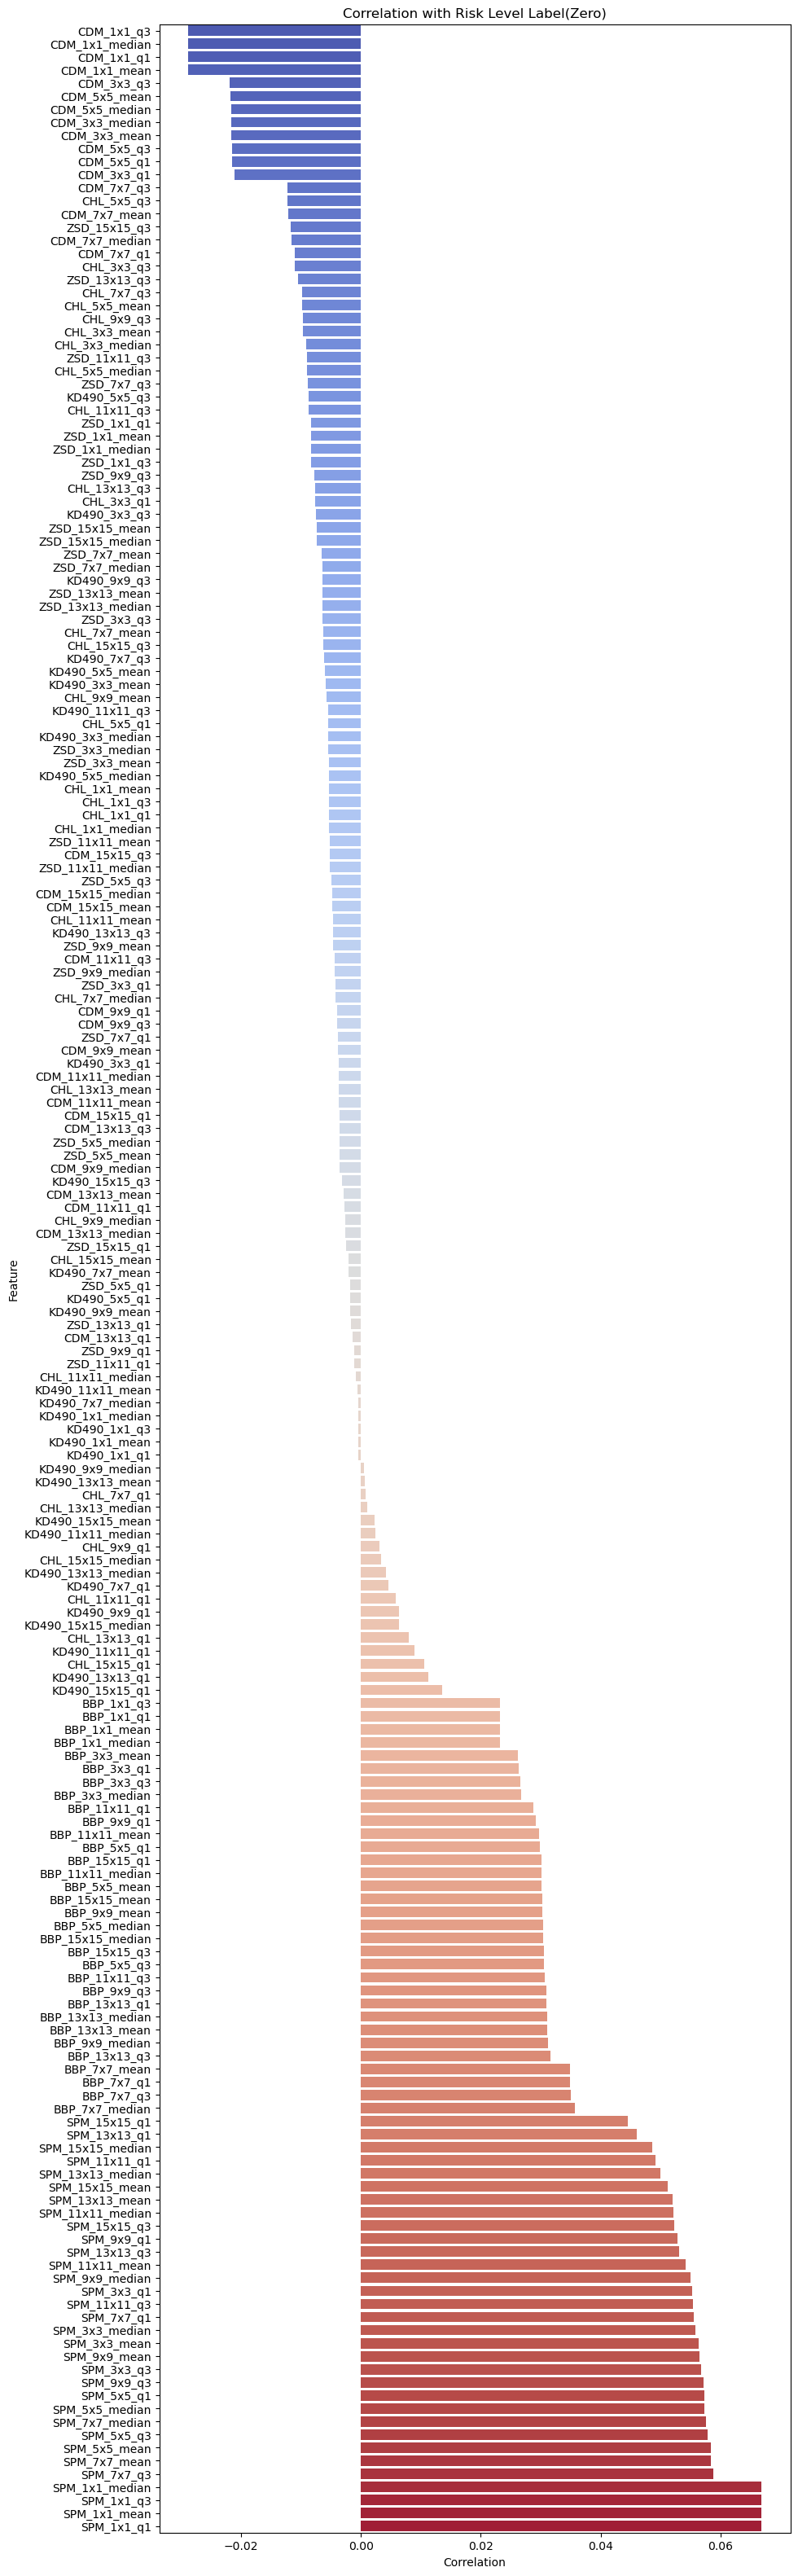

In [37]:
correlation_df = df.drop(columns=['riskLevelLabel', 'time', 'site']).corrwith(df['riskLevelLabel']).reset_index()
correlation_df.columns = ['Feature', 'Correlation']
correlation_df = correlation_df.sort_values(by='Correlation', ascending=True)

plt.figure(figsize=(10, 40))
sns.barplot(x='Correlation', y='Feature', data=correlation_df, palette='coolwarm')
plt.title('Correlation with Risk Level Label')
plt.show()

#### Feature Dataset filled with Neg

In [10]:
df_neg = pd.merge(riskforecasting, feature_neg, on=['site','time'])
df_neg

,site,time,riskLevelLabel,BBP_1x1_median,CDM_1x1_median,SPM_1x1_median,KD490_1x1_median,ZSD_1x1_median,CHL_1x1_median,BBP_1x1_mean,...,SPM_15x15_q1,KD490_15x15_q1,ZSD_15x15_q1,CHL_15x15_q1,BBP_15x15_q3,CDM_15x15_q3,SPM_15x15_q3,KD490_15x15_q3,ZSD_15x15_q3,CHL_15x15_q3
0,ukc1101-06000,2020-05-14,0.0,0.014399,0.648437,9.016005,0.720255,1.359252,26.936116,0.014399,...,5.846387,0.720255,1.359252,26.936116,0.014399,0.648437,5.846387,0.720255,1.359252,26.936116
1,ukc1101-06000,2020-05-15,0.0,-10.000000,-10.000000,8.102808,0.393628,1.778462,10.588528,-10.000000,...,8.102808,0.393628,1.778462,10.588528,-10.000000,-10.000000,8.102808,0.393628,1.778462,10.588528
2,ukc1101-06000,2020-05-16,0.0,-10.000000,-10.000000,1.135922,0.263305,2.588783,5.632908,-10.000000,...,1.135922,0.263305,2.588783,5.632908,-10.000000,-10.000000,1.135922,0.263305,2.588783,5.632908
3,ukc1101-06000,2020-05-17,0.0,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,...,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000
4,ukc1101-06000,2020-05-18,0.0,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,...,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187107,ukk4307-33900,2022-09-26,0.0,-10.000000,-10.000000,7.356489,0.183889,3.869243,3.158081,-10.000000,...,7.356489,0.183889,3.869243,3.158081,-10.000000,-10.000000,7.356489,0.183889,3.869243,3.158081
187108,ukk4307-33900,2022-09-27,0.0,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,...,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000,-10.000000
187109,ukk4307-33900,2022-09-28,0.0,-10.000000,-10.000000,4.906127,0.142344,5.219365,2.063839,-10.000000,...,4.906127,0.142344,5.219365,2.063839,-10.000000,-10.000000,4.906127,0.142344,5.219365,2.063839
187110,ukk4307-33900,2022-09-29,0.0,-10.000000,-10.000000,9.181858,0.151466,4.857575,2.291730,-10.000000,...,9.181858,0.151466,4.857575,2.291730,-10.000000,-10.000000,9.181858,0.151466,4.857575,2.291730


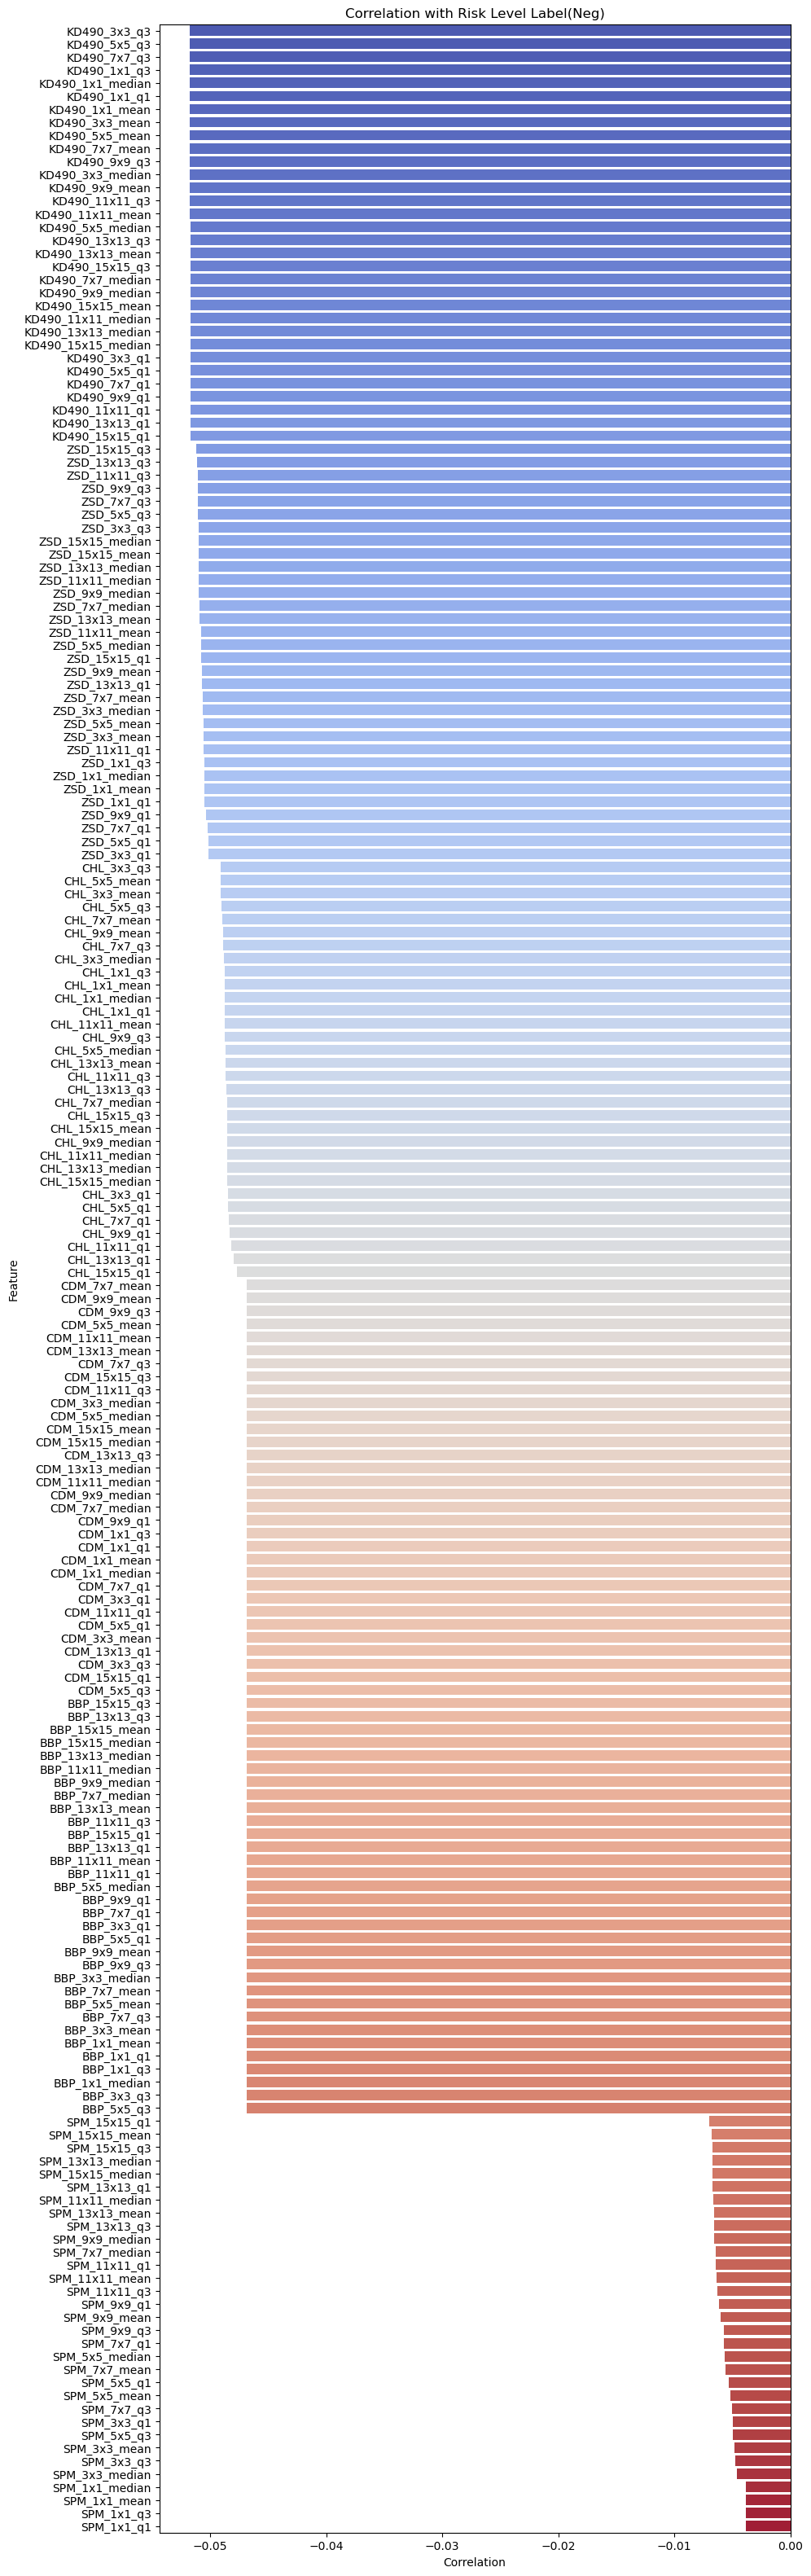

In [13]:
correlation_df_neg = df_neg.drop(columns=['riskLevelLabel', 'time', 'site']).corrwith(df_neg['riskLevelLabel']).reset_index()
correlation_df_neg.columns = ['Feature', 'Correlation']
correlation_df_neg = correlation_df_neg.sort_values(by='Correlation', ascending=True)

plt.figure(figsize=(10, 40))
sns.barplot(x='Correlation', y='Feature', data=correlation_df_neg, palette='coolwarm')
plt.title('Correlation with Risk Level Label(Neg)')
plt.show()

#### Feature Dataset filled with Zero

In [11]:
df_zero = pd.merge(riskforecasting, feature_zero, on=['site','time'])
df_zero

,site,time,riskLevelLabel,BBP_1x1_median,CDM_1x1_median,SPM_1x1_median,KD490_1x1_median,ZSD_1x1_median,CHL_1x1_median,BBP_1x1_mean,...,SPM_15x15_q1,KD490_15x15_q1,ZSD_15x15_q1,CHL_15x15_q1,BBP_15x15_q3,CDM_15x15_q3,SPM_15x15_q3,KD490_15x15_q3,ZSD_15x15_q3,CHL_15x15_q3
0,ukc1101-06000,2020-05-14,0.0,0.014399,0.648437,9.016005,0.720255,1.359252,26.936116,0.014399,...,5.846387,0.720255,1.359252,26.936116,0.014399,0.648437,5.846387,0.720255,1.359252,26.936116
1,ukc1101-06000,2020-05-15,0.0,0.000000,0.000000,8.102808,0.393628,1.778462,10.588528,0.000000,...,8.102808,0.393628,1.778462,10.588528,0.000000,0.000000,8.102808,0.393628,1.778462,10.588528
2,ukc1101-06000,2020-05-16,0.0,0.000000,0.000000,1.135922,0.263305,2.588783,5.632908,0.000000,...,1.135922,0.263305,2.588783,5.632908,0.000000,0.000000,1.135922,0.263305,2.588783,5.632908
3,ukc1101-06000,2020-05-17,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,ukc1101-06000,2020-05-18,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187107,ukk4307-33900,2022-09-26,0.0,0.000000,0.000000,7.356489,0.183889,3.869243,3.158081,0.000000,...,7.356489,0.183889,3.869243,3.158081,0.000000,0.000000,7.356489,0.183889,3.869243,3.158081
187108,ukk4307-33900,2022-09-27,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
187109,ukk4307-33900,2022-09-28,0.0,0.000000,0.000000,4.906127,0.142344,5.219365,2.063839,0.000000,...,4.906127,0.142344,5.219365,2.063839,0.000000,0.000000,4.906127,0.142344,5.219365,2.063839
187110,ukk4307-33900,2022-09-29,0.0,0.000000,0.000000,9.181858,0.151466,4.857575,2.291730,0.000000,...,9.181858,0.151466,4.857575,2.291730,0.000000,0.000000,9.181858,0.151466,4.857575,2.291730


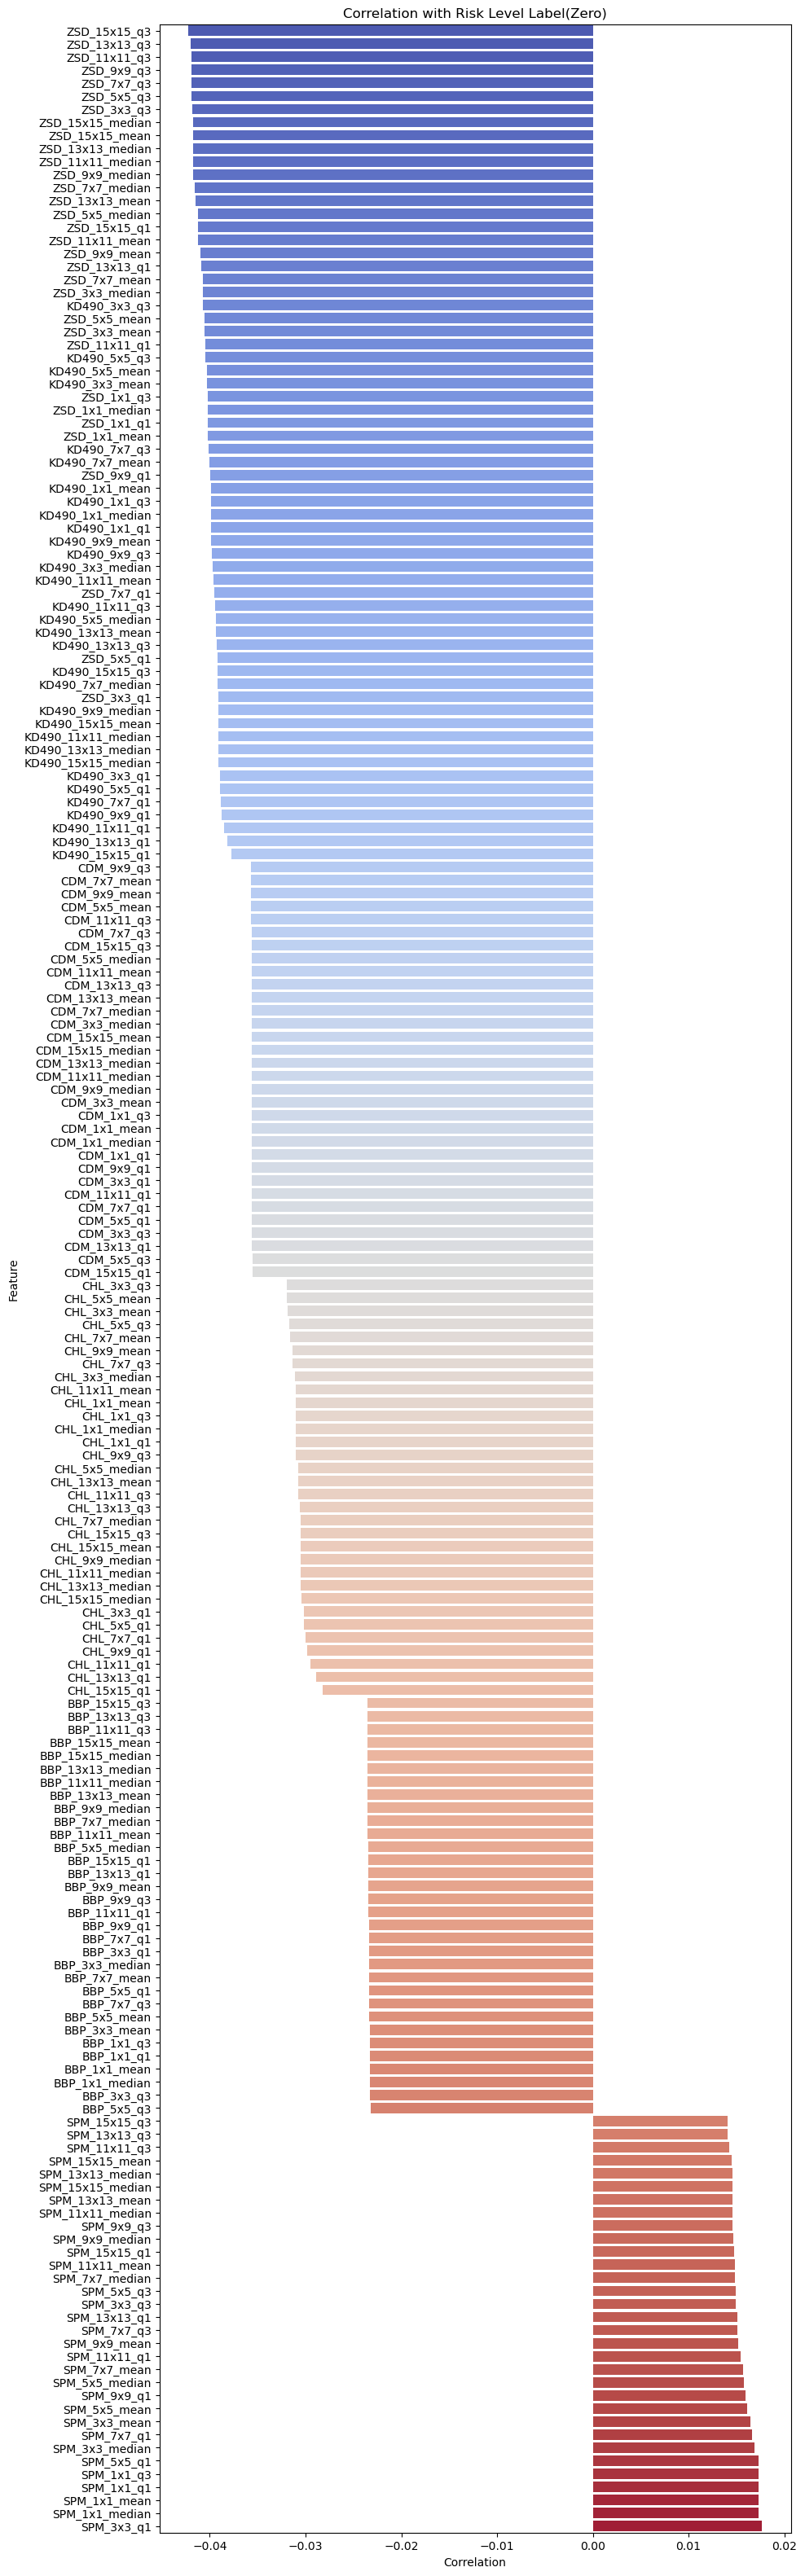

In [14]:
correlation_df_zero = df_zero.drop(columns=['riskLevelLabel', 'time', 'site']).corrwith(df_neg['riskLevelLabel']).reset_index()
correlation_df_zero.columns = ['Feature', 'Correlation']
correlation_df_zero = correlation_df_zero.sort_values(by='Correlation', ascending=True)

plt.figure(figsize=(10, 40))
sns.barplot(x='Correlation', y='Feature', data=correlation_df_zero, palette='coolwarm')
plt.title('Correlation with Risk Level Label(Zero)')
plt.show()

### 15x15 window sized mean

#### Feature Dataset without filling Missing Value

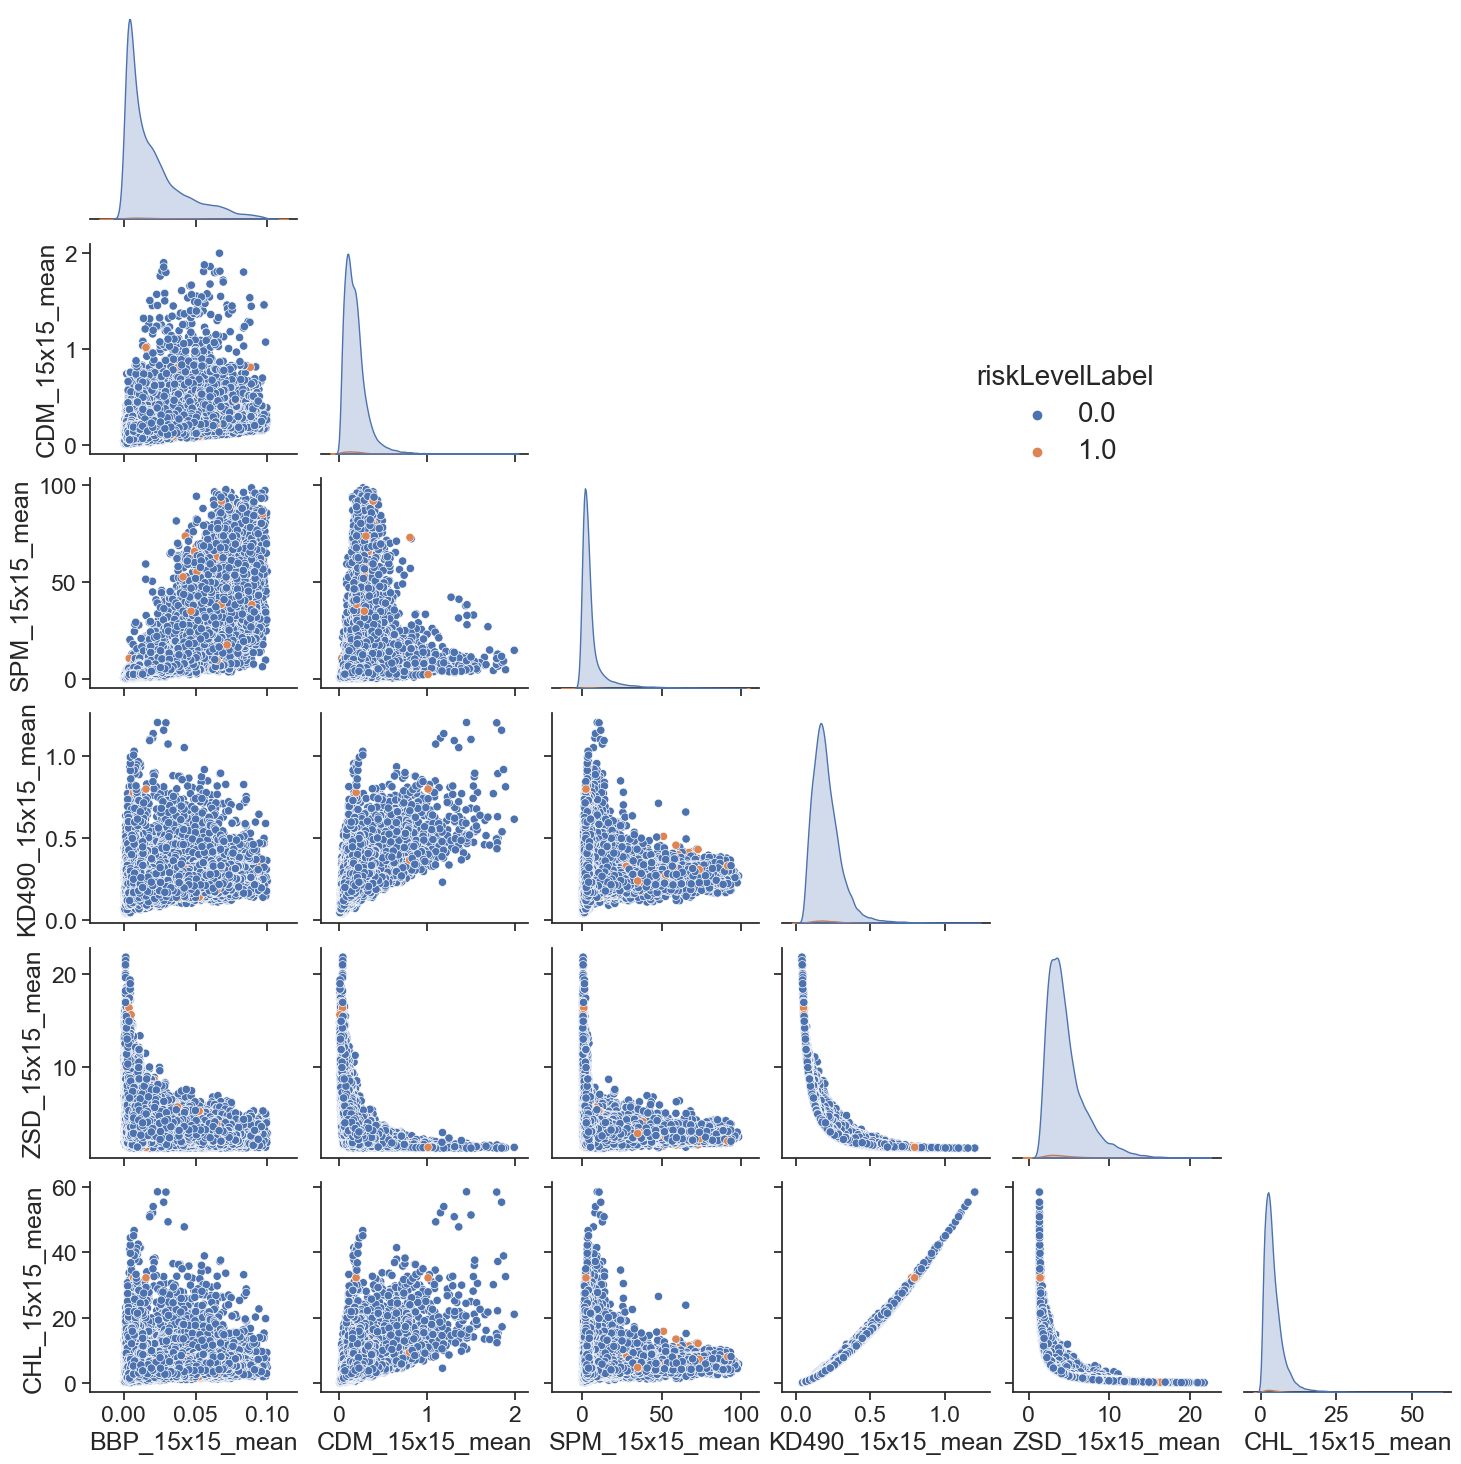

In [32]:
corr_columns_neg = ['riskLevelLabel'] + [col for col in df.columns if col.endswith('15x15_mean')]
subset_df = df[corr_columns_neg].dropna()

sns.set(font_scale=1.5, style='ticks')
g = sns.pairplot(subset_df, hue='riskLevelLabel', corner=True)

g._legend.set_bbox_to_anchor((0.7,0.7))
for text in g._legend.texts:
    text.set_fontsize(20)
g._legend.get_title().set_fontsize(20)

plt.show()

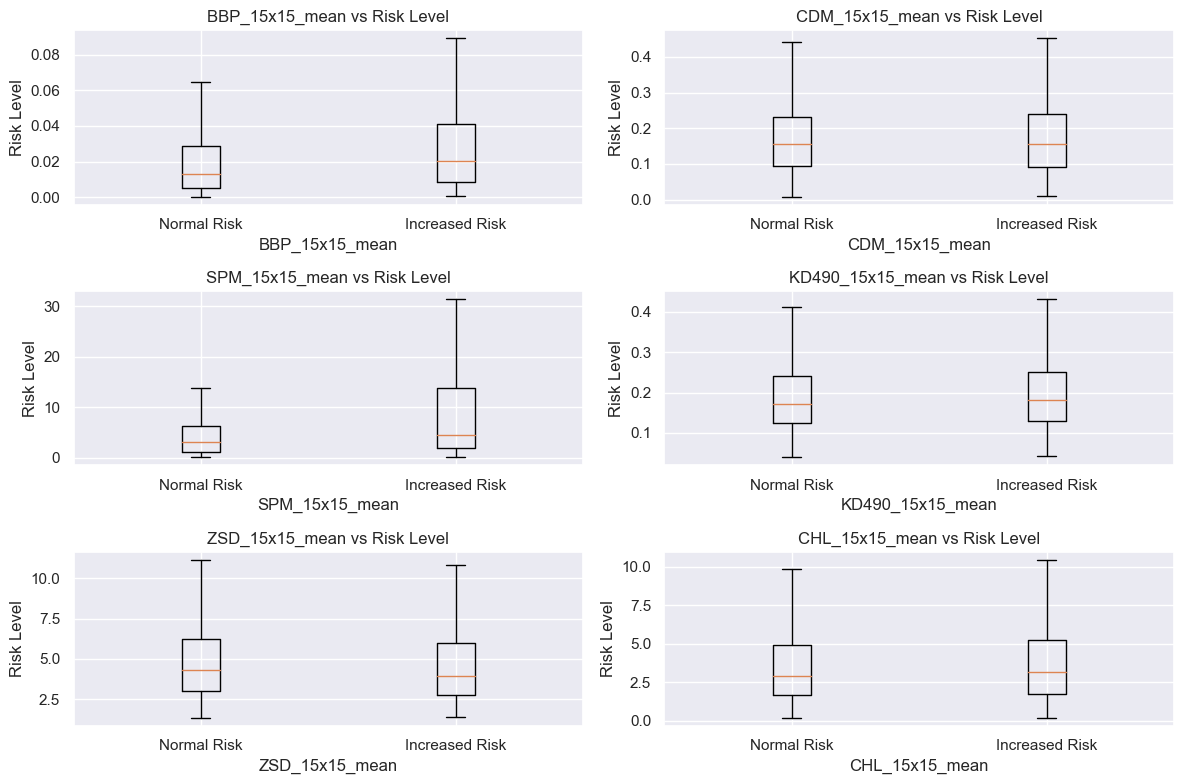

In [40]:
labels = [x for x in df.columns if '15x15_mean' in x]

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 8))
sns.set(font_scale=1)

for i, column in enumerate(labels):
    row = i // 2
    col = i % 2
    
    ax = axes[row, col]
    g = ax.boxplot([df.loc[df["riskLevelLabel"] == 0, labels[i]].dropna(),
                    df.loc[df["riskLevelLabel"] == 1, labels[i]].dropna()],
                    labels=["Normal Risk", "Increased Risk"], showfliers=False)
    ax.set_xlabel(labels[i])
    ax.set_ylabel("Risk Level")
    ax.set_title(f"{column} vs Risk Level")

plt.tight_layout()

#### Feature Dataset filled with Neg

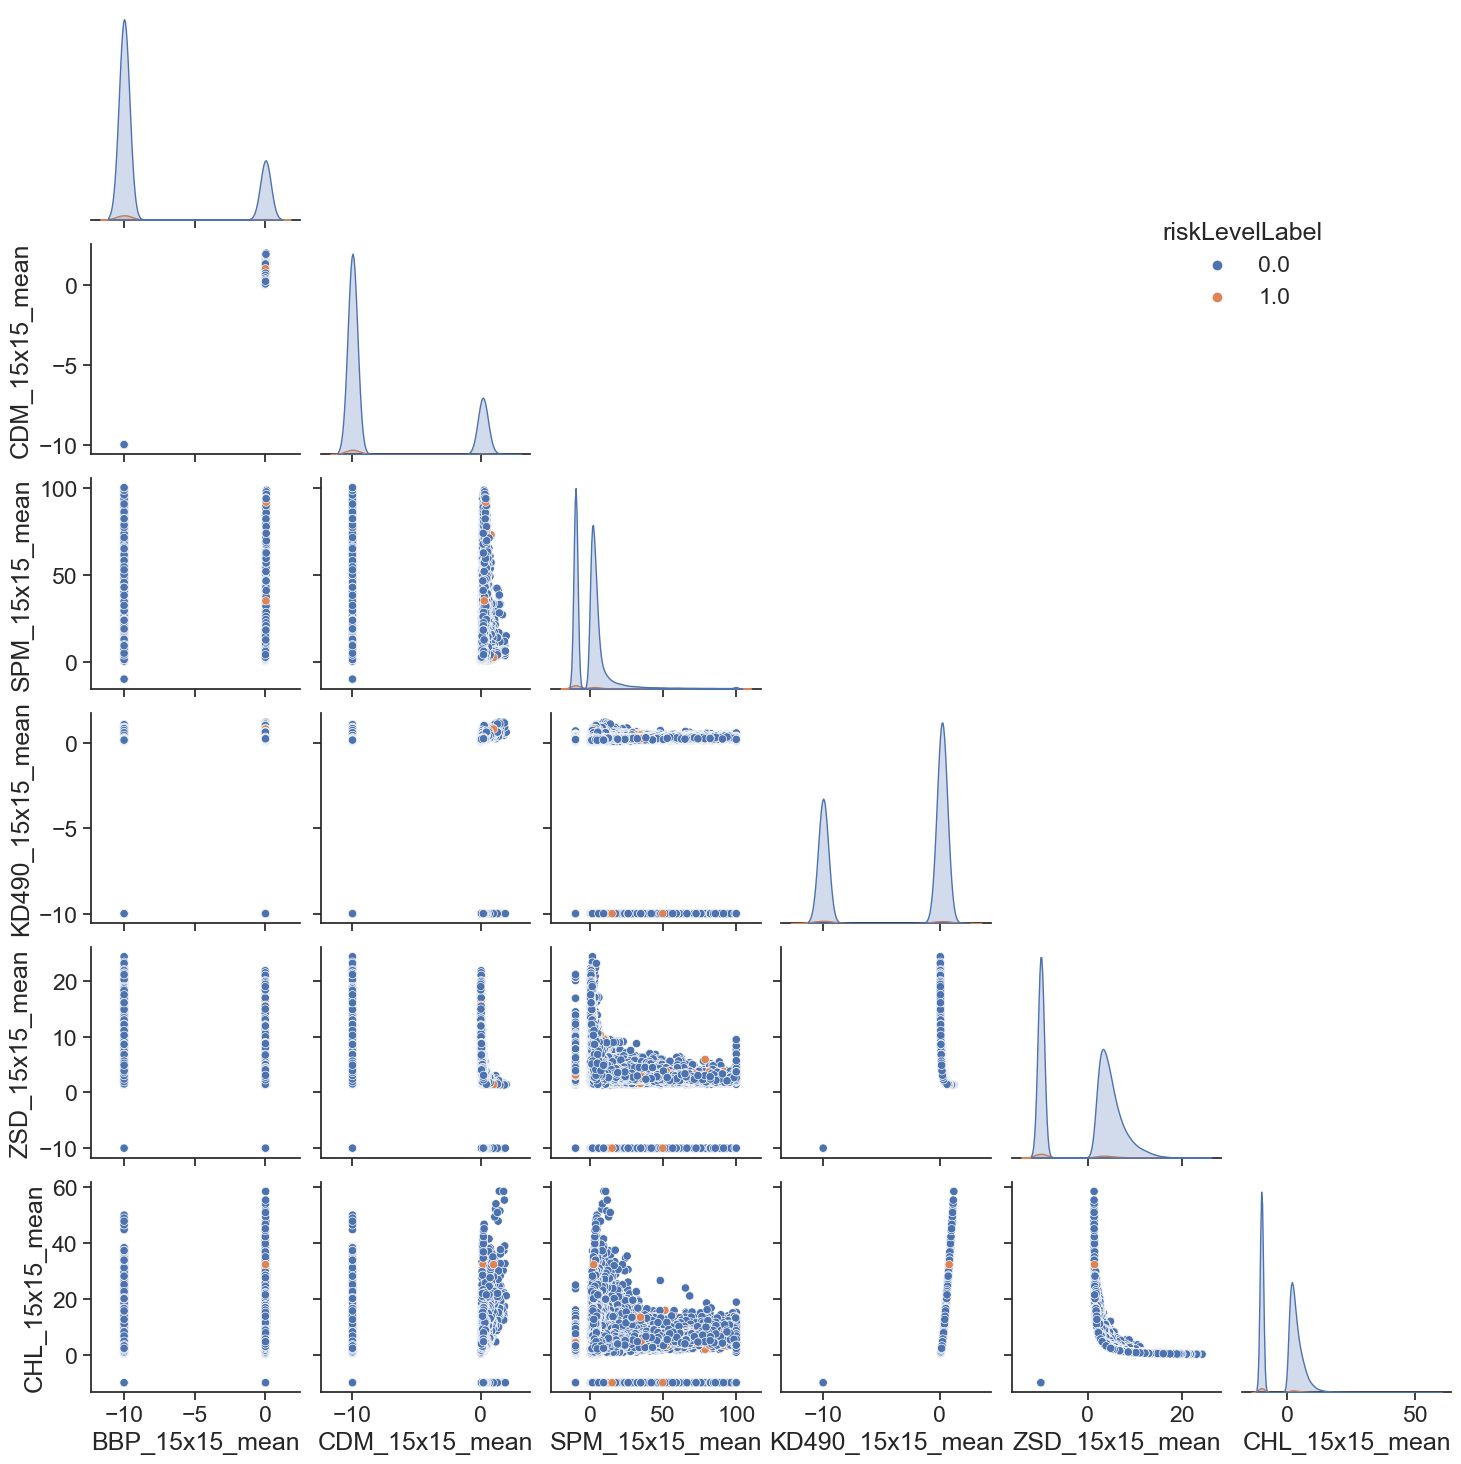

In [27]:
corr_columns_neg = ['riskLevelLabel'] + [col for col in df_neg.columns if col.endswith('15x15_mean')]
subset_df_neg = df_neg[corr_columns_neg].dropna()

sns.set(font_scale=1.5, style='ticks')
g = sns.pairplot(subset_df_neg, hue='riskLevelLabel', corner=True)

g._legend.set_bbox_to_anchor((0.8,0.8))

plt.show()

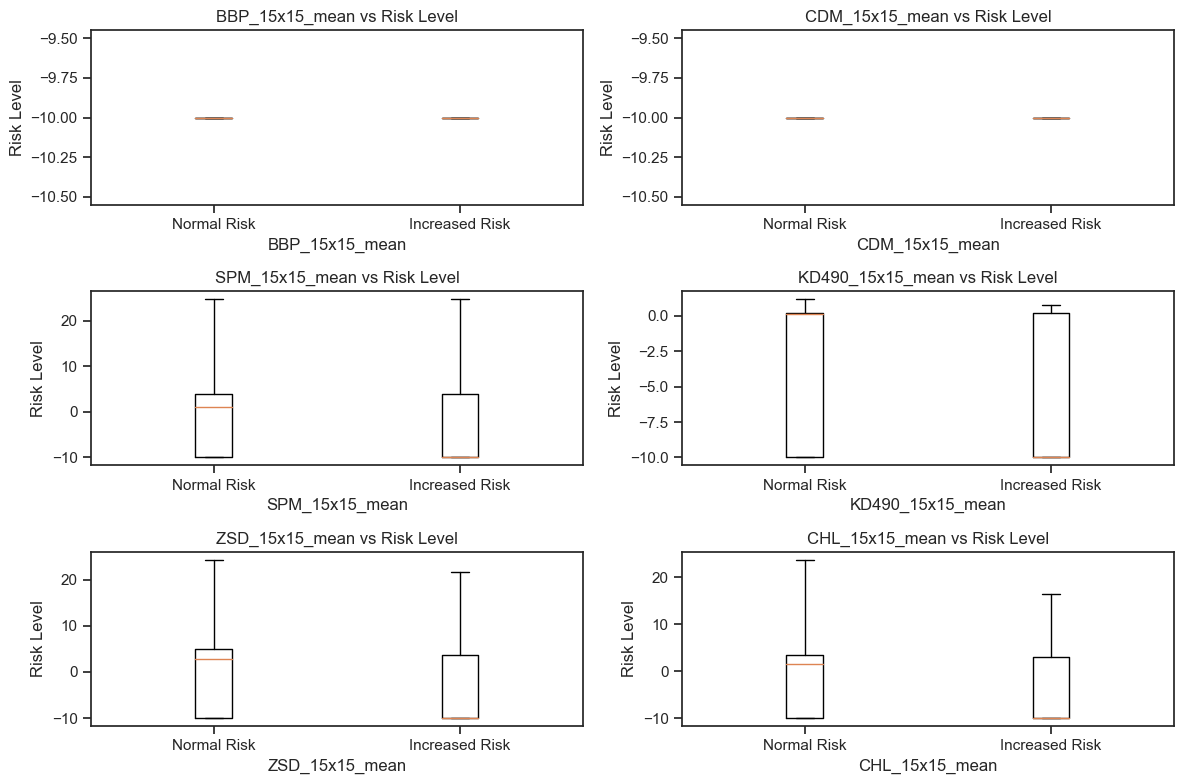

In [22]:
labels = [x for x in df_neg.columns if '15x15_mean' in x]

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 8))

for i, column in enumerate(labels):
    row = i // 2
    col = i % 2
    
    ax = axes[row, col]
    ax.boxplot([df_neg.loc[df_neg["riskLevelLabel"] == 0, labels[i]].dropna(),
                df_neg.loc[df_neg["riskLevelLabel"] == 1, labels[i]].dropna()],
               labels=["Normal Risk", "Increased Risk"], showfliers=False)
    ax.set_xlabel(labels[i])
    ax.set_ylabel("Risk Level")
    ax.set_title(f"{column} vs Risk Level")

plt.tight_layout()

#### Feature Dataset filled with Zero

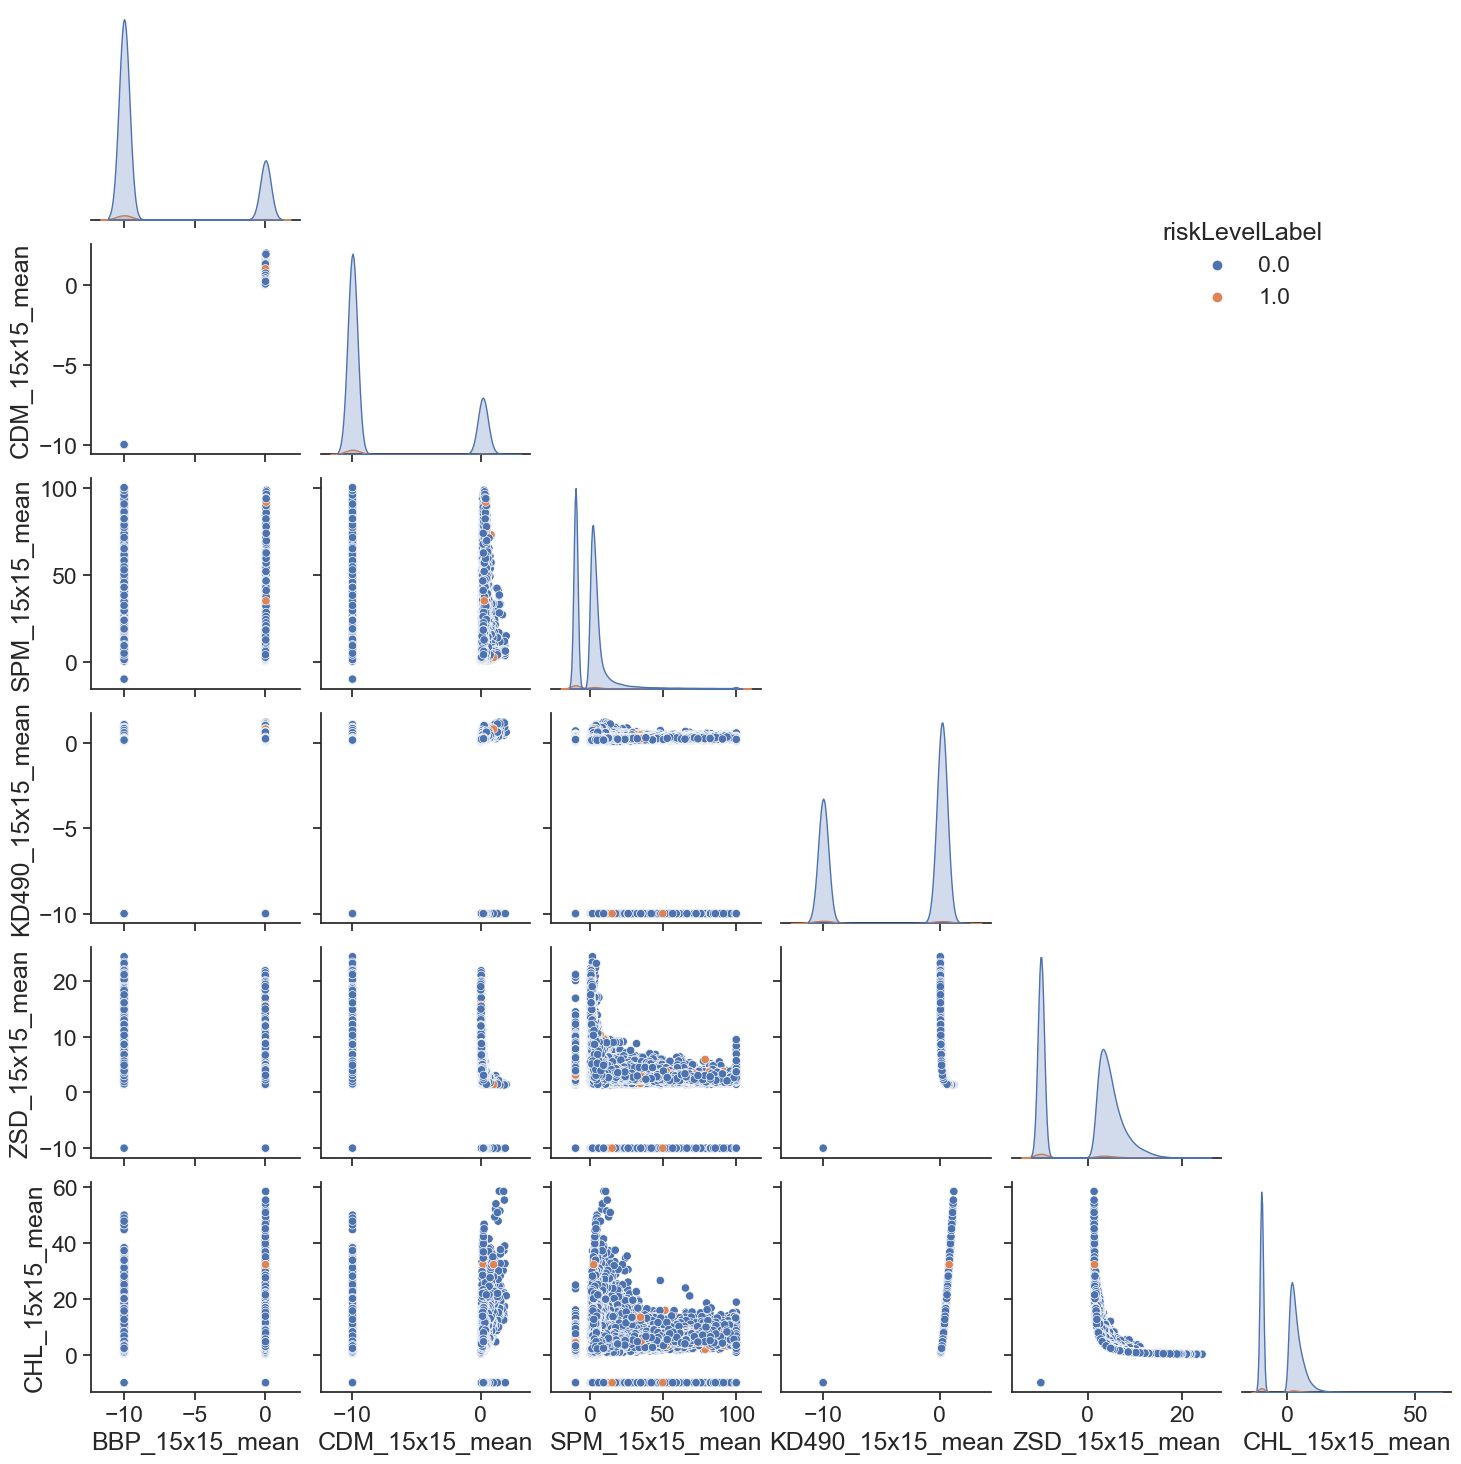

In [28]:
corr_columns_zero = ['riskLevelLabel'] + [col for col in df_zero.columns if col.endswith('15x15_mean')]
subset_df_zero = df_zero[corr_columns_zero].dropna()

sns.set(font_scale=1.5, style='ticks')
g = sns.pairplot(subset_df_neg, hue='riskLevelLabel', corner=True)

g._legend.set_bbox_to_anchor((0.8,0.8))

plt.show()

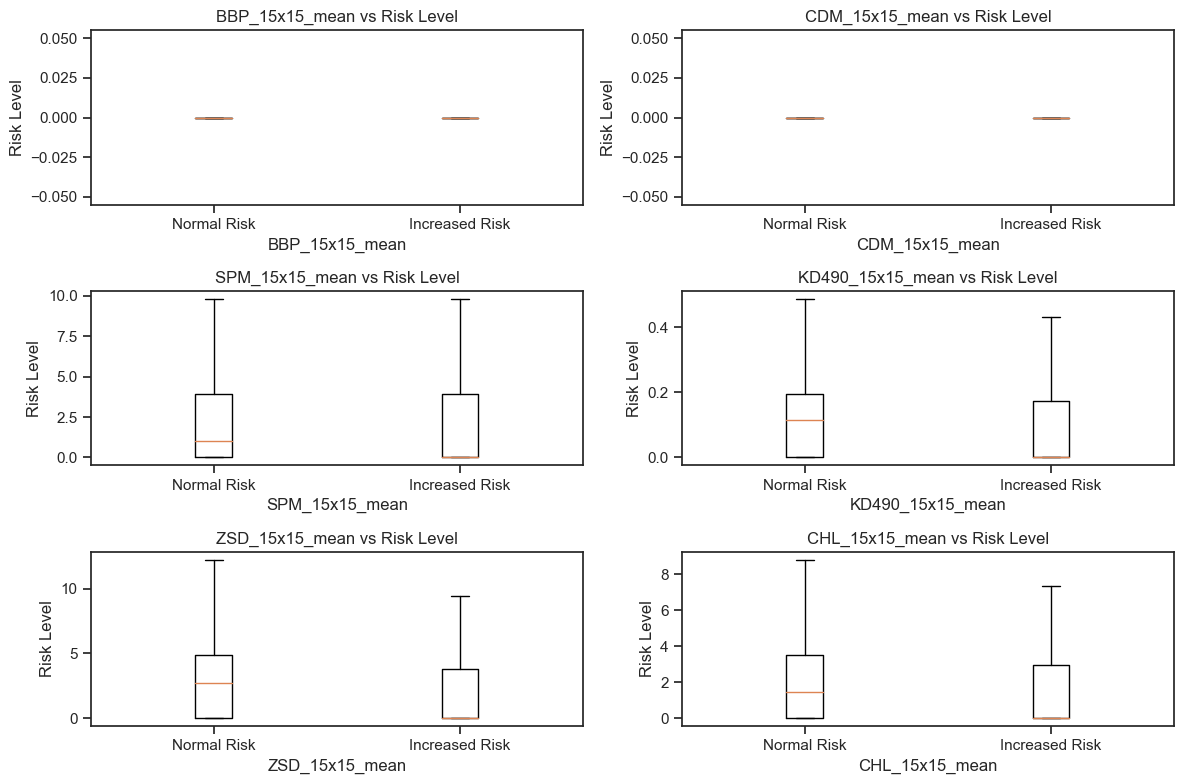

In [24]:
labels = [x for x in df_zero.columns if '15x15_mean' in x]

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 8))

for i, column in enumerate(labels):
    row = i // 2
    col = i % 2
    
    ax = axes[row, col]
    ax.boxplot([df_zero.loc[df_zero["riskLevelLabel"] == 0, labels[i]].dropna(),
                df_zero.loc[df_zero["riskLevelLabel"] == 1, labels[i]].dropna()],
               labels=["Normal Risk", "Increased Risk"], showfliers=False)
    ax.set_xlabel(labels[i])
    ax.set_ylabel("Risk Level")
    ax.set_title(f"{column} vs Risk Level")

plt.tight_layout()

### 5x5 window sized median

#### Feature Dataset without filling Missing Value

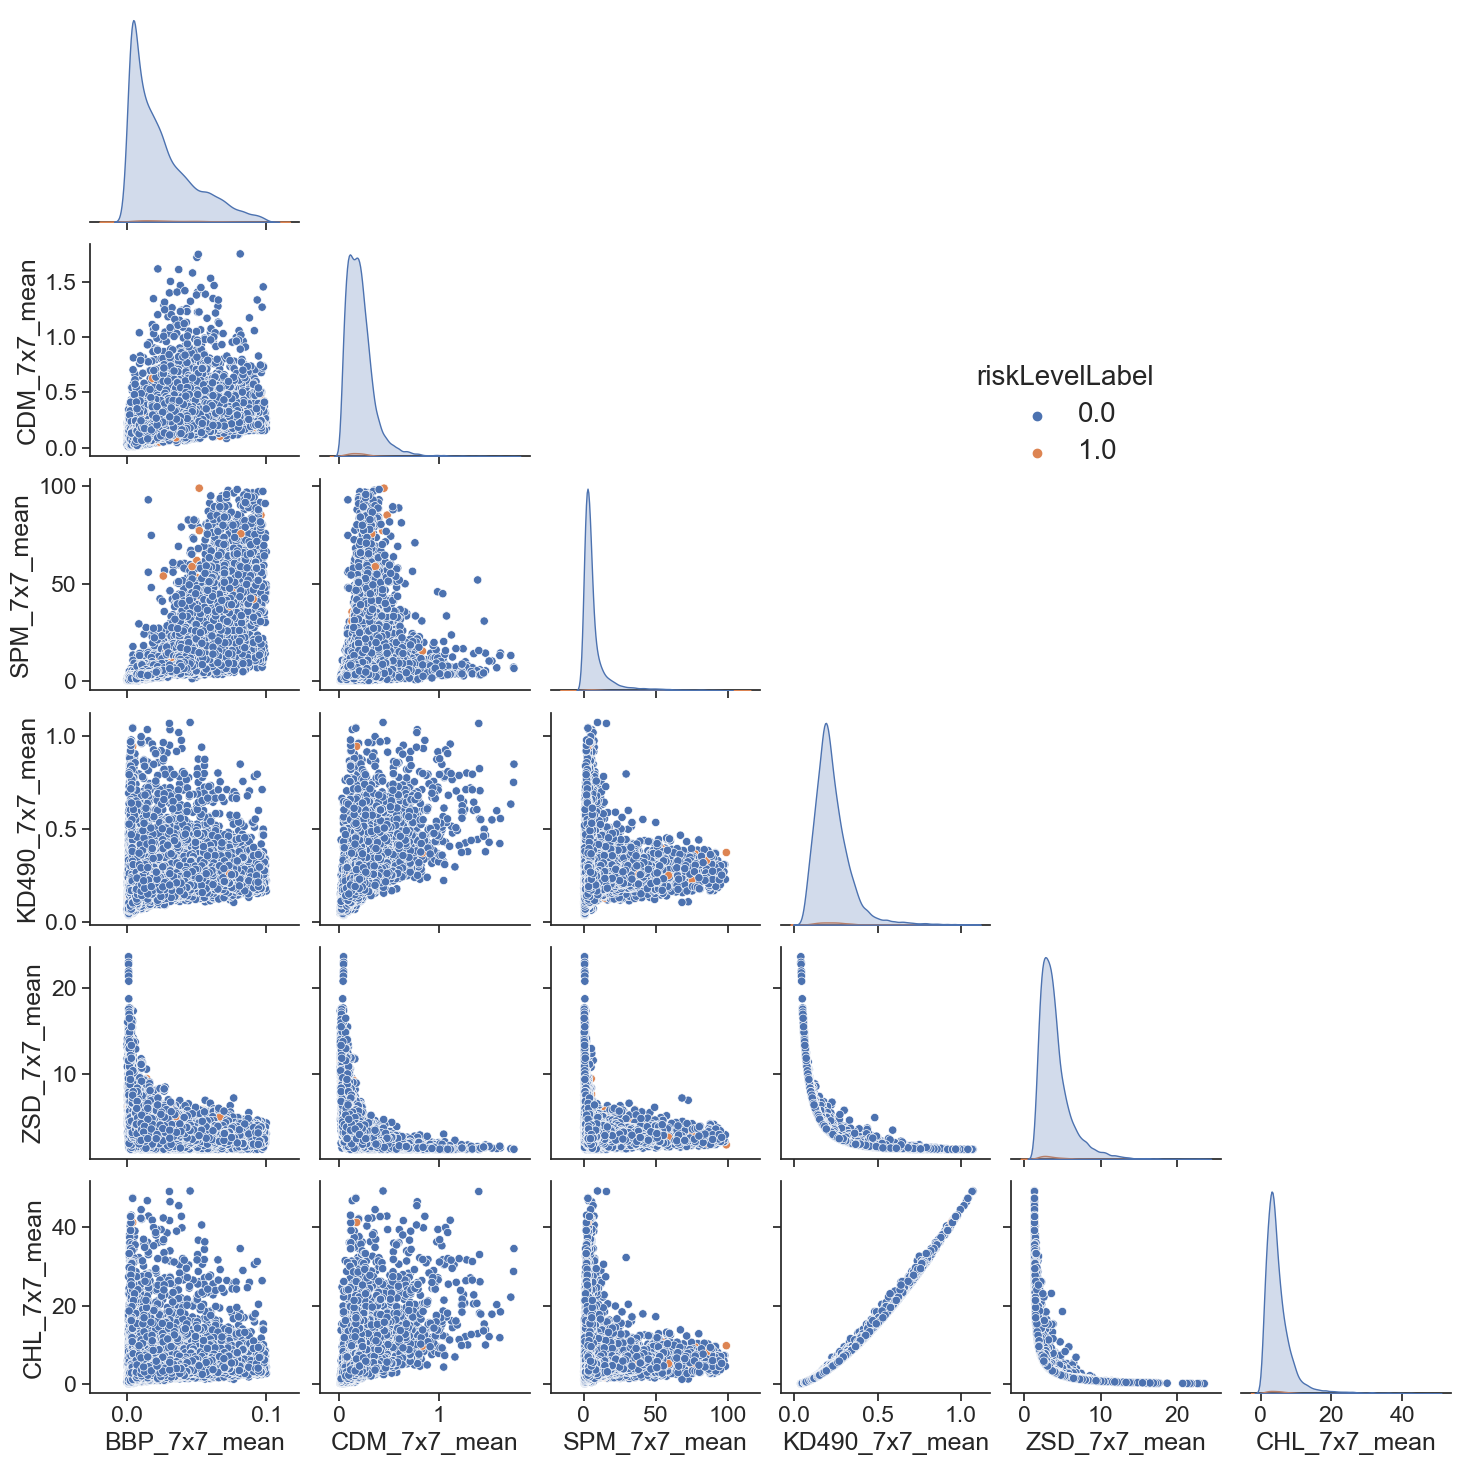

In [66]:
corr_columns_neg = ['riskLevelLabel'] + [col for col in df.columns if col.endswith('7x7_mean')]
subset_df = df[corr_columns_neg].dropna()

sns.set(font_scale=1.5, style='ticks')
g = sns.pairplot(subset_df, hue='riskLevelLabel', corner=True)

g._legend.set_bbox_to_anchor((0.7,0.7))
for text in g._legend.texts:
    text.set_fontsize(20)
g._legend.get_title().set_fontsize(20)

plt.show()

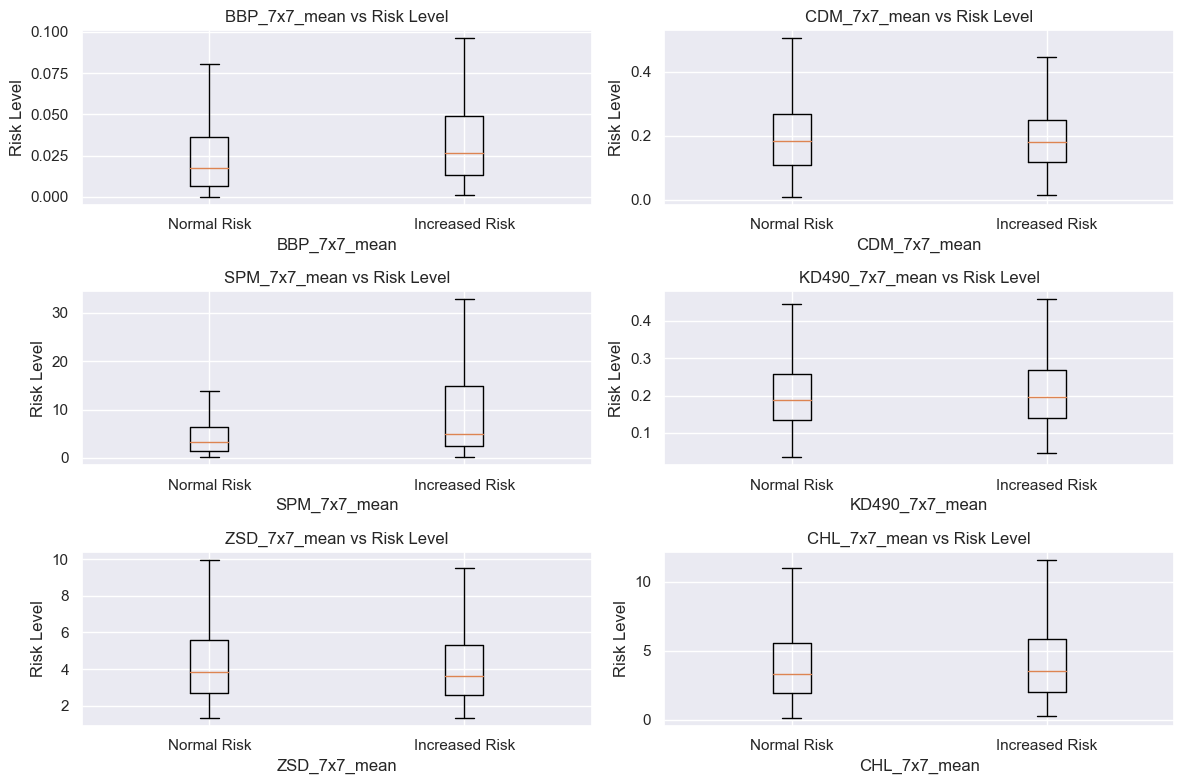

In [68]:
labels = [x for x in df.columns if '7x7_mean' in x]

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 8))
sns.set(font_scale=1)

for i, column in enumerate(labels):
    row = i // 2
    col = i % 2
    
    ax = axes[row, col]
    g = ax.boxplot([df.loc[df["riskLevelLabel"] == 0, labels[i]].dropna(),
                    df.loc[df["riskLevelLabel"] == 1, labels[i]].dropna()],
                    labels=["Normal Risk", "Increased Risk"], showfliers=False)
    ax.set_xlabel(labels[i])
    ax.set_ylabel("Risk Level")
    ax.set_title(f"{column} vs Risk Level")

plt.tight_layout()